[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohsennasab/python-fundamentals-hh/blob/main/notebooks/05_stream-data/Module5_USGSDataRetrieval.ipynb)

# Module 5: USGS Data Retrieval for H&H Modeling
## Accessing Real-World Gauge Data for Model Calibration and Validation

### Welcome!
This module teaches you how to access USGS stream gauge data programmatically - a skill that's essential for model calibration, validation, and real-time operations. By the end, you'll have automated workflows for finding, retrieving, and processing real gauge data.

### What You'll Work Through Today:
- Understand USGS data architecture and parameter codes
- Find gauges within your study watershed
- Retrieve streamflow, stage, and temperature data
- Process time series for H&H model input
- Create professional gauge catalogs
- Build automated data retrieval workflows
- Export data for H&H modeling workflows

### Module Structure:
1. **Mental Models** - How USGS organizes water data
2. **Data Basics** - Understanding parameter codes and data types
3. **Workspace Setup** - Installing dataretrieval library
4. **Watershed Upload** - Loading your study area
5. **Gauge Discovery** - Finding monitoring locations
6. **Data Retrieval** - Downloading time series
7. **Processing & QC** - Gap filling and resampling
8. **Professional Outputs** - Catalogs and exports
9. **What You Can Now Do** - Complete data workflow

## Part 1: Mental Models - USGS Water Data Architecture 🧠

### The USGS National Water Information System (NWIS)

Think of USGS NWIS as a **massive, real-time database** of water measurements across the US:
- **15,000+ active gauges** measuring continuously
- **100+ years** of historical records
- **15-minute updates** for real-time data
- **Free, public access** via web services

### Key Concepts

**1. Site Numbers (Station IDs)**
- Unique 8-15 digit identifier (e.g., "08074500")
- Like a gauge's "social security number"
- Consistent across all USGS databases

**2. Parameter Codes**
- 5-digit codes for measured variables
- Essential codes for H&H:

| Code | Parameter | Units | H&H Use |
|------|-----------|-------|----------|
| 00060 | Discharge (Flow) | cfs | Model calibration |
| 00065 | Gage Height (Stage) | ft | Boundary conditions |
| 00010 | Water Temperature | °C | Water quality |
| 00055 | Stream Velocity | ft/s | Hydraulics |

**3. Data Types**
- **IV (Instantaneous Values)**: 15-minute data for real-time/events
- **DV (Daily Values)**: Daily statistics for long-term analysis

### The Engineering Workflow

```
Your Watershed → Find Nearby Gauges → Retrieve Data → Process → Model Input
```

### Why This Matters

**Manual approach** (what you've been doing):
1. Visit USGS website
2. Click through pages
3. Download CSV files
4. Clean in Excel
5. Format for model
⏰ **Time: 2-4 hours per gauge**

**Automated approach** (what you'll learn today):
1. Run Python script
2. Get all gauges and data
⏰ **Time: 5 minutes for 20+ gauges**

### Today's Scenario

You have a watershed and need:
1. All available gauges within 10 miles
2. Last 5 years of flow and stage data
3. Formatted for model calibration

Let's automate this entire workflow!

## Part 2: Understanding USGS Data Structure 📚

### USGS Web Services

USGS provides data through REST APIs:
- **Base URL**: `https://waterservices.usgs.gov/nwis/`
- **Formats**: JSON, RDB (tab-delimited), WaterML
- **Rate limits**: Be respectful (1 request/second)

### Data Quality Codes

USGS marks data quality:
- **A**: Approved for publication
- **P**: Provisional (subject to revision)
- **e**: Estimated

### Common Issues

1. **Data gaps**: Equipment failure, maintenance
2. **Ice-affected**: Winter measurements unreliable
3. **Datum changes**: Reference elevation shifts
4. **Rating curve updates**: Stage-discharge relationship changes

## Using AI in This Module

This module introduces the USGS `dataretrieval` library, which has its own conventions for querying data. If a function call or its parameters look unfamiliar, ask your AI:

- *"What does `nwis.get_iv()` do and what parameters does it take?"*
- *"I got an empty DataFrame back from my USGS query. What might be wrong?"*
- *"How do I find all USGS gauges within 10 miles of a specific point?"*

The USGS API can be finicky sometimes (network timeouts, empty results for certain areas). If something doesn't work, the error message plus your AI assistant will usually get you unstuck quickly.

## Part 3: Setting Up Your Data Retrieval Workspace 🛠️

### Installing Required Libraries for USGS Data Access and Interactive Mapping

In this module, we use several Python libraries to download, analyze, and visualize hydrologic and geospatial data.

```python
!pip install -q dataretrieval geopandas folium contextily requests
```

Here is what each library does:

- **dataretrieval**  
  A Python library developed by the USGS for downloading hydrologic and water-resources data directly from services such as:
  - streamflow
  - groundwater
  - water quality
  - site metadata

  Website:  
  https://doi-usgs.github.io/dataretrieval-python/

---

- **GeoPandas**  
  Used for reading, analyzing, and visualizing spatial vector datasets such as:
  - shapefiles
  - GeoJSON files
  - watershed boundaries
  - rivers and floodplains

  Website:  
  https://geopandas.org/

---

- **Folium**  
  Used to create interactive web maps directly in Python notebooks. Folium maps can:
  - zoom
  - pan
  - display layers
  - show popups and tooltips

  Website:  
  https://python-visualization.github.io/folium/

---

- **Contextily**  
  Adds web basemaps (such as OpenStreetMap or satellite imagery) to GeoPandas plots.

  This is especially useful for adding geographic context to maps.

  Website:  
  https://contextily.readthedocs.io/

---

- **Requests**  
  A general-purpose Python library used to send web requests and work with APIs.

  Many hydrology and GIS workflows use APIs to download:
  - weather data
  - streamflow data
  - raster datasets
  - metadata

  Website:  
  https://requests.readthedocs.io/

---

💡 These libraries form a powerful toolkit for modern hydrology, GIS, and H&H workflows in Python.

In [3]:
# Install USGS data retrieval library and dependencies
!pip install -q dataretrieval geopandas folium contextily requests

print("USGS dataretrieval library installed.")
print("Documentation: https://doi-usgs.github.io/dataretrieval-python/")

USGS dataretrieval library installed.
Documentation: https://doi-usgs.github.io/dataretrieval-python/


The `dataretrieval` package is the official USGS Python library for accessing their water data. It handles all the API calls behind the scenes so you don't need to worry about constructing URLs or parsing responses yourself.

In [4]:
# Import all necessary libraries
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point, Polygon
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import contextily as cx
from datetime import datetime, timedelta
import folium
import json
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# USGS dataretrieval
import dataretrieval
import dataretrieval.nwis as nwis

# Set default plot style
try:
    plt.style.use('seaborn-v0_8-darkgrid')
except OSError:
    plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (12, 6)

print("Libraries imported successfully!")
print(f"Dataretrieval version: {dataretrieval.__version__ if hasattr(dataretrieval, '__version__') else 'Unknown'}")

Libraries imported successfully!
Dataretrieval version: 1.4.0


### What did we just import?

Most of these are familiar from earlier modules. The new one is `dataretrieval.nwis`, which provides functions like:
- `nwis.get_info()` - find gauge sites by location, parameter, or site number
- `nwis.get_iv()` - download instantaneous (15-minute) data
- `nwis.get_dv()` - download daily values

The `matplotlib.dates` module helps format date axes on time series plots.

If `plt.style.use(...)` gives you a warning, that's fine - it just means the exact style name changed between matplotlib versions. The fallback style works just as well.

### Define USGS Parameter Codes

We'll create a reference dictionary for easy use:

### Why define these codes?

Every measurement type in USGS has a 5-digit parameter code. Rather than remembering that `00060` means discharge, we store them in a dictionary so the code reads like plain English: `USGS_PARAMETERS['discharge']` instead of a magic number.

You can look up any parameter code at the USGS website, or ask your AI: *"What is the USGS parameter code for suspended sediment concentration?"*

In [5]:
# USGS Parameter codes reference
USGS_PARAMETERS = {
    'discharge': '00060',  # Streamflow in cubic feet per second
    'flow': '00060',       # Alias for discharge
    'stage': '00065',      # Gage height in feet
    'temperature': '00010', # Water temperature in Celsius
    'velocity': '00055',   # Stream velocity in feet per second
    'turbidity': '63680',  # Turbidity in FNU
    'dissolved_oxygen': '00300', # DO in mg/L
    'ph': '00400',         # pH in standard units
    'conductance': '00095' # Specific conductance in uS/cm
}

# Display available parameters
print("Available USGS Parameters:")
print("="*50)
for name, code in USGS_PARAMETERS.items():
    print(f"  {name:20} : {code}")

# Most common for H&H modeling
print("\n🎯 Primary H&H Parameters:")
print("  - Discharge (00060): For model calibration")
print("  - Stage (00065): For boundary conditions")
print("  - Temperature (00010): For water quality models")

Available USGS Parameters:
  discharge            : 00060
  flow                 : 00060
  stage                : 00065
  temperature          : 00010
  velocity             : 00055
  turbidity            : 63680
  dissolved_oxygen     : 00300
  ph                   : 00400
  conductance          : 00095

🎯 Primary H&H Parameters:
  - Discharge (00060): For model calibration
  - Stage (00065): For boundary conditions
  - Temperature (00010): For water quality models


## Part 4: Loading Your Study Watershed 🗺️

The study area for this module is a real **HUC-8 watershed**, not a hand-drawn box. HUC-8 ("Hydrologic Unit Code, level 8") is the standard way the USGS and state agencies divide the country into nested drainage basins, and it is a natural unit for finding the gauges that drain an area.

We use the **Minnesota DNR watershed suite**, which bundles several watershed layers in a single shapefile ZIP. We will load the HUC-8 "major" watersheds layer, then keep the one watershed that contains our demo gauge, **USGS-05331000 (Mississippi River at St. Paul)**. That basin is the *Mississippi River - Twin Cities* watershed (HUC-8 `07010206`), and it holds several long-record gauges along the Mississippi, Minnesota, and St. Croix rivers.

In [6]:
# Upload the watershed boundary file
from google.colab import files

print("Please upload the watershed file for this module:")
print("   dnr_huc8_watersheds.zip  (from notebooks/05_stream-data/data/)")
print()
print("This holds the Minnesota DNR HUC-8 'major' watersheds layer.")
print()
print("Click 'Choose Files' below...")

uploaded = files.upload()

print(f"\nUploaded {len(uploaded)} file(s):")
for filename in uploaded.keys():
    print(f"   - {filename}")

Please upload the watershed file for this module:
   dnr_huc8_watersheds.zip  (from notebooks/05_stream-data/data/)

This holds the Minnesota DNR HUC-8 'major' watersheds layer.

Click 'Choose Files' below...


Saving dnr_huc8_watersheds.zip to dnr_huc8_watersheds.zip

Uploaded 1 file(s):
   - dnr_huc8_watersheds.zip


In [7]:
# Load the HUC-8 watershed layer from the DNR shapefile ZIP
#
# A shapefile is really several files (.shp, .shx, .dbf, .prj) bundled together.
# This ZIP holds the Minnesota DNR HUC-8 "major" watersheds layer. To read a
# named shapefile from inside a ZIP, GeoPandas uses the
# "zip://archive.zip!layer.shp" syntax.
uploaded_files = list(uploaded.keys())

# Find the uploaded ZIP
zip_candidates = [f for f in uploaded_files if f.lower().endswith('.zip')]
if not zip_candidates:
    raise FileNotFoundError(
        "No ZIP found. Please upload dnr_huc8_watersheds.zip."
    )
zip_file = zip_candidates[0]

# The HUC-8 'major' watersheds layer inside the DNR ZIP
HUC8_LAYER = 'dnr_watersheds_dnr_level_04_huc_08_majors.shp'

print(f"Loading {HUC8_LAYER}")
print(f"  from {zip_file} ...")
watersheds = gpd.read_file(f'zip://{zip_file}!{HUC8_LAYER}')

print(f"\nLoaded {len(watersheds)} HUC-8 watersheds")
print(f"CRS: {watersheds.crs}")
print("\nColumns available:")
for col in watersheds.columns:
    if col != 'geometry':
        print(f"  - {col}")

Loading dnr_watersheds_dnr_level_04_huc_08_majors.shp
  from dnr_huc8_watersheds.zip ...

Loaded 80 HUC-8 watersheds
CRS: EPSG:26915

Columns available:
  - major_name
  - acres
  - sq_miles
  - prod_year
  - source
  - HUC_8
  - HUC4
  - Shape_Leng
  - Shape_Area
  - major


### What did we just load?

The DNR ZIP holds an entire watershed suite, so reading it means pointing GeoPandas at one specific shapefile inside the archive. That is what the `zip://...!dnr_watersheds_dnr_level_04_huc_08_majors.shp` path does.

The result is a `GeoDataFrame` named `watersheds` with all 80 HUC-8 "major" watersheds in Minnesota. The columns that matter most to us are:

- **`HUC_8`** - the eight-digit hydrologic unit code (a unique ID for each basin)
- **`major_name`** - a readable name for the watershed
- **`sq_miles`** - the basin area the DNR reports

Notice the CRS is already a projected one (UTM Zone 15N, meters), which is exactly what we want for the area and distance calculations later.

### Select the Watershed That Contains Our Gauge

Out of all 80 HUC-8 watersheds, we want the single one our demo gauge sits inside. We filter the table by the HUC-8 code `07010206`, the *Mississippi River - Twin Cities* basin. To study a different basin later, you only need to change this one code (or filter by `major_name` instead).

In [8]:
# Select the HUC-8 watershed that contains our demo gauge (USGS-05331000)
#
# 07010206 is the "Mississippi River - Twin Cities" basin. Filtering by the
# HUC_8 code keeps just that one watershed. To study a different basin, swap
# in another HUC_8 code, or filter on the major_name column instead.
TARGET_HUC8 = '07010206'

# Compare as clean text so a stray space or number type does not break the match
huc_codes = watersheds['HUC_8'].astype(str).str.strip()
selected_watershed = watersheds[huc_codes == TARGET_HUC8].copy()

# Stop early with a clear message if the code was not found
if len(selected_watershed) == 0:
    raise ValueError(
        f"HUC-8 {TARGET_HUC8} not found in this file. "
        f"Example codes available: {sorted(huc_codes.unique())[:5]} ..."
    )

print("Selected watershed:")
print(f"  Name:  {selected_watershed['major_name'].values[0]}")
print(f"  HUC-8: {selected_watershed['HUC_8'].values[0]}")
print(f"  DNR reported area: {selected_watershed['sq_miles'].values[0]:,} sq mi")

# The DNR data is already projected (meters), so we can report the area now.
# Part 5 confirms the CRS and uses it for buffering.
if selected_watershed.crs and selected_watershed.crs.is_projected:
    area_km2 = selected_watershed.geometry.area.values[0] / 1_000_000
    print(f"  Computed area:     {area_km2:.1f} km²")
else:
    print("  Area will be computed after reprojection in Part 5.")

Selected watershed:
  Name:  Mississippi River - Twin Cities
  HUC-8: 07010206
  DNR reported area: 1,007 sq mi
  Computed area:     2607.2 km²


## Part 5: CRS Normalization and Buffering 🌍

### Critical Step: Ensure Proper Coordinate System

For accurate buffering, we need a projected CRS (meters/feet), not geographic (degrees).

### Why reproject and why buffer?

Two practical reasons:

1. **Work in a projected CRS (meters).** Distance and area in a geographic CRS (degrees) are not meaningful. The DNR watershed data already comes projected (UTM Zone 15N, meters), so the code below confirms that and uses it directly. If your data were in lat/lon, the same code would reproject it to the correct UTM zone first.

2. **Buffer the watershed.** USGS gauges just outside the watershed boundary can still be useful (a gauge a short distance downstream still tells you about flow leaving the basin). A 5 to 20 km buffer is a reasonable compromise between catching nearby gauges and keeping the search focused.

In [9]:
# Check whether the watershed has a Coordinate Reference System (CRS)
#
# A CRS tells us how spatial coordinates relate
# to real-world locations on Earth.
#
# If no CRS exists, GeoPandas does not know
# what coordinate system the data uses.
if selected_watershed.crs is None:

    # Print a warning message
    print("⚠️ No CRS defined. Assuming WGS84 (EPSG:4326)")

    # Assign WGS84 latitude/longitude coordinates
    #
    # EPSG:4326 is the standard geographic CRS
    # used by GPS and many web maps.
    selected_watershed = selected_watershed.set_crs('EPSG:4326')

# Check whether the CRS is projected
#
# Geographic CRS:
# - uses degrees
# - not ideal for area and distance calculations
#
# Projected CRS:
# - uses meters or feet
# - appropriate for accurate area calculations
if not selected_watershed.crs.is_projected:

    # Print the current CRS
    print(f"Current CRS is geographic ({selected_watershed.crs})")

    # Find the centroid of the watershed
    #
    # The centroid is the approximate center point
    # of the polygon.
    centroid = selected_watershed.geometry.centroid.values[0]

    # Extract longitude from the centroid
    lon = centroid.x

    # Estimate the appropriate UTM zone
    #
    # UTM divides the Earth into 6-degree-wide zones.
    #
    # This formula converts longitude into a UTM zone number.
    utm_zone = int((lon + 180) / 6) + 1

    # Determine whether the watershed is in the
    # northern or southern hemisphere
    #
    # Different EPSG codes are used for each hemisphere.
    if centroid.y >= 0:

        # Northern hemisphere UTM EPSG code
        #
        # Example:
        # UTM Zone 13N = EPSG:32613
        epsg_code = 32600 + utm_zone

    else:

        # Southern hemisphere UTM EPSG code
        #
        # Example:
        # UTM Zone 13S = EPSG:32713
        epsg_code = 32700 + utm_zone

    # Print reprojection information
    print(
        f"Reprojecting to UTM Zone {utm_zone} "
        f"(EPSG:{epsg_code})..."
    )

    # Reproject the watershed to the selected UTM CRS
    #
    # UTM coordinates are stored in meters,
    # making them appropriate for:
    # - area calculations
    # - distance measurements
    # - buffering operations
    selected_watershed_proj = selected_watershed.to_crs(
        f'EPSG:{epsg_code}'
    )

else:

    # If the CRS is already projected,
    # no reprojection is needed.
    print(f"Already in projected CRS: {selected_watershed.crs}")

    # Create a copy of the dataset
    selected_watershed_proj = selected_watershed.copy()

# Calculate watershed area
#
# geometry.area returns area in square units
# of the projected CRS.
#
# Since UTM uses meters:
# - area is in square meters
#
# Divide by 1,000,000 to convert to square kilometers.
area_km2 = (
    selected_watershed_proj.geometry.area.values[0]
    / 1_000_000
)

# Print the final watershed area
print(f"\n✅ Watershed area: {area_km2:.2f} km²")

Already in projected CRS: EPSG:26915

✅ Watershed area: 2607.20 km²


### Apply a Buffer Around the Study Area

In [10]:
# Define the buffer distance around the watershed
#
# A buffer creates an expanded zone around a feature.
#
# In hydrology and GIS workflows, buffers are commonly used to:
# - search for nearby stream gages
# - include nearby rainfall stations
# - capture nearby infrastructure
# - expand study areas
#
# Typical search buffers might range from:
# - 5 km
# - 10 km
# - 20 km
buffer_distance_km = 10

# Convert kilometers to meters
#
# Most projected CRS units are in meters,
# so buffering operations should also use meters.
buffer_distance_m = buffer_distance_km * 1000

# Print buffer information
print(
    f"Applying {buffer_distance_km} km buffer around watershed..."
)

# Create a copy of the watershed GeoDataFrame
#
# This preserves the original watershed geometry.
buffered_watershed_proj = selected_watershed_proj.copy()

# Create the buffer geometry
#
# geometry.buffer(distance) expands the polygon outward
# by the specified distance.
#
# Since the CRS is projected in meters,
# the buffer distance is also interpreted in meters.
buffered_watershed_proj['geometry'] = (
    selected_watershed_proj.geometry.buffer(buffer_distance_m)
)

# Calculate the buffered area
#
# geometry.area returns square meters
# because the CRS is projected in meters.
#
# Divide by 1,000,000 to convert to square kilometers.
buffered_area_km2 = (
    buffered_watershed_proj.geometry.area.values[0]
    / 1_000_000
)

# Print original watershed area
print(f"Original area: {area_km2:.2f} km²")

# Print buffered area
print(f"Buffered area: {buffered_area_km2:.2f} km²")

# Calculate how much the search area increased
#
# Example:
# - 100% means the area doubled
# - 200% means the area tripled
print(
    f"Search area increased by: "
    f"{((buffered_area_km2 / area_km2 - 1) * 100):.1f}%"
)

# Reproject both datasets back to WGS84
#
# Many web services and APIs, including USGS services,
# expect coordinates in:
# EPSG:4326 (latitude/longitude)
selected_watershed_wgs = selected_watershed_proj.to_crs(
    'EPSG:4326'
)

buffered_watershed_wgs = buffered_watershed_proj.to_crs(
    'EPSG:4326'
)

Applying 10 km buffer around watershed...
Original area: 2607.20 km²
Buffered area: 5749.06 km²
Search area increased by: 120.5%


### Visualize Study Area and Buffer

The dark blue polygon is the HUC-8 watershed (Mississippi River - Twin Cities). The light blue area is the search buffer added around it, and the red star marks the watershed centroid. We will query USGS for any gauges inside the buffered area, then keep only the ones that fall inside the watershed plus its buffer.

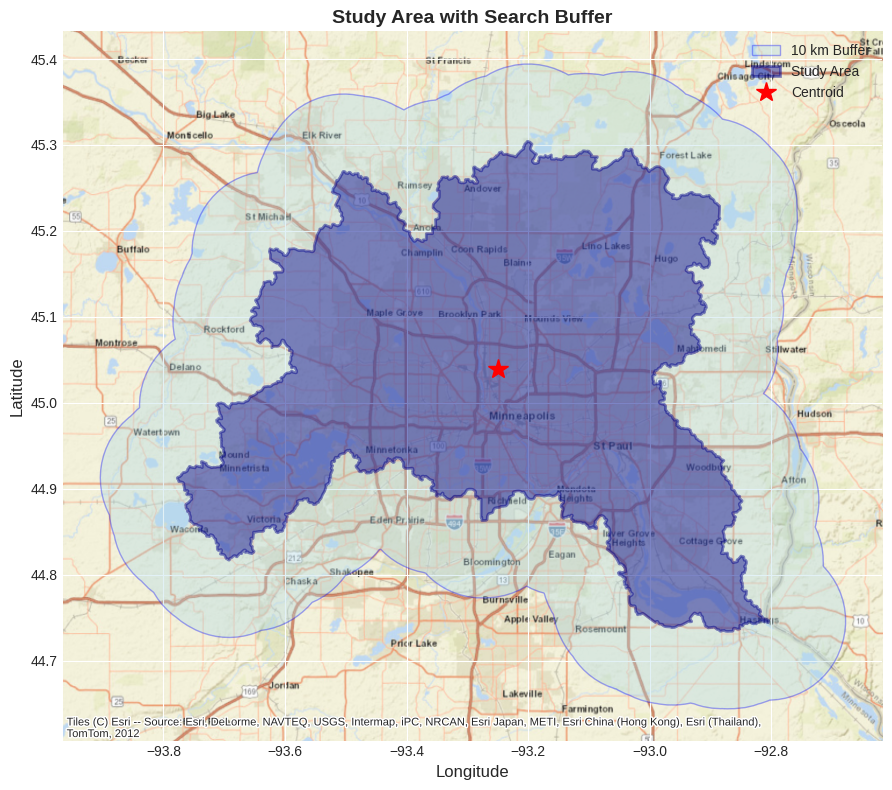

In [31]:
# Visualize the study area and search buffer on a basemap
#
# This map helps us confirm that:
# - the watershed is in the expected location
# - the buffer was created correctly
# - the centroid looks reasonable
# - the study area is ready for nearby USGS gage searches

# Create a figure and plotting area
fig, ax = plt.subplots(figsize=(10, 8))

# Plot the buffered watershed
#
# This shows the larger search area around the watershed.
# We use a lighter color and partial transparency
# so the study area and basemap remain visible.
buffered_watershed_wgs.plot(
    ax=ax,
    color='lightblue',
    alpha=0.35,
    edgecolor='blue',
    linewidth=1,
    label=f'{buffer_distance_km} km Buffer'
)

# Plot the original study area
#
# This is the main watershed boundary.
selected_watershed_wgs.plot(
    ax=ax,
    color='darkblue',
    alpha=0.45,
    edgecolor='darkblue',
    linewidth=2,
    label='Study Area'
)

# Calculate the centroid of the watershed
#
# The centroid is the approximate center point
# of the polygon.
centroid = selected_watershed_wgs.geometry.centroid.values[0]

# Plot the centroid as a red star
ax.plot(
    centroid.x,
    centroid.y,
    'r*',
    markersize=15,
    label='Centroid'
)

# Add an Esri World Street Map basemap
#
# contextily can add web basemaps behind GeoPandas plots.
#
# We tell contextily that our data is in EPSG:4326
# so it can align the basemap correctly.
try:
    cx.add_basemap(
        ax,
        crs='EPSG:4326',
        source=cx.providers.Esri.WorldStreetMap #Esri.WorldStreetMap, OpenTopoMap
    )

# If the basemap fails to load, continue without stopping the notebook.
#
# This can happen if there is no internet connection
# or if the tile server is temporarily unavailable.
except Exception as e:
    print(f"Could not load basemap (continuing without one): {e}")

# Add x-axis label
#
# Since the data is in EPSG:4326,
# the x-axis represents longitude.
ax.set_xlabel('Longitude', fontsize=12)

# Add y-axis label
#
# Since the data is in EPSG:4326,
# the y-axis represents latitude.
ax.set_ylabel('Latitude', fontsize=12)

# Add a title to the map
ax.set_title(
    'Study Area with Search Buffer',
    fontsize=14,
    fontweight='bold'
)

# Add a legend to identify map layers
ax.legend(loc='upper right')

# Automatically adjust spacing
plt.tight_layout()

# Display the final map
plt.show()

## Part 6: Finding USGS Gauges in Your Area 🔍

### Query USGS for Monitoring Locations

We'll use the bounding box of our buffered watershed to find gauges:

In [12]:
# Get the bounding box for the USGS query
#
# total_bounds returns:
# west, south, east, north
#
# Because buffered_watershed_wgs is in EPSG:4326,
# these values are in longitude and latitude.
west, south, east, north = buffered_watershed_wgs.total_bounds

# Print the bounding box coordinates
#
# These coordinates define the search area
# used to find nearby USGS monitoring locations.
print(f"Searching for USGS gauges in bounding box:")
print(f"  West: {west:.4f}°")
print(f"  South: {south:.4f}°")
print(f"  East: {east:.4f}°")
print(f"  North: {north:.4f}°")

# Query USGS NWIS for stream monitoring locations
#
# NWIS stands for National Water Information System.
#
# In this example, we search for sites with:
# - 00060 = discharge
# - 00065 = gage height / stage
#
# siteType='ST' limits the search to stream sites.
# siteStatus='all' includes both active and inactive sites.
try:

    # Print a message before starting the query
    print("\nQuerying USGS NWIS for monitoring locations...")

    # Request USGS sites within the bounding box
    sites_df, _ = nwis.get_info(
        bBox=f"{west:.6f},{south:.6f},{east:.6f},{north:.6f}",
        parameterCd='00060,00065',
        siteType='ST',
        siteStatus='all'
    )

    # Check whether any sites were returned
    if len(sites_df) > 0:

        # Print the number of USGS gauges found
        print(f"\n✅ Found {len(sites_df)} USGS gauge(s) in bounding box")

        # Convert the pandas DataFrame to a GeoDataFrame
        #
        # dec_long_va = longitude
        # dec_lat_va = latitude
        #
        # gpd.points_from_xy() creates point geometries
        # from longitude and latitude columns.
        sites_gdf = gpd.GeoDataFrame(
            sites_df,
            geometry=gpd.points_from_xy(
                sites_df.dec_long_va,
                sites_df.dec_lat_va
            ),
            crs='EPSG:4326'
        )

        # Display a brief gauge summary
        print("\nGauge summary:")

        # Show selected columns for the first 10 gauges
        print(
            sites_gdf[
                [
                    'site_no',
                    'station_nm',
                    'dec_lat_va',
                    'dec_long_va'
                ]
            ].head(10)
        )

    else:

        # If no gauges were found, print a helpful message
        print("\n⚠️ No USGS gauges found in bounding box")
        print("Try increasing the buffer distance or checking a different area.")

        # Create an empty GeoDataFrame so later code does not fail
        sites_gdf = gpd.GeoDataFrame()

# Catch errors so the notebook does not crash
#
# Errors may happen because of:
# - no internet connection
# - USGS service issues
# - API request limits
# - unexpected response format
except Exception as e:

    # Print the error message
    print(f"\n❌ Error querying USGS: {str(e)}")

    # Print a beginner-friendly explanation
    print("This might be due to network issues or API limitations.")

    # Create an empty GeoDataFrame so later code can still run safely
    sites_gdf = gpd.GeoDataFrame()

Searching for USGS gauges in bounding box:
  West: -93.9046°
  South: 44.6448°
  East: -92.6784°
  North: 45.3947°

Querying USGS NWIS for monitoring locations...

✅ Found 98 USGS gauge(s) in bounding box

Gauge summary:
    site_no                                       station_nm  dec_lat_va  \
0  05274900              ST. FRANCIS RIVER NEAR BIG LAKE, MN   45.385256   
1  05275000                      ELK RIVER NEAR BIG LAKE, MN   45.333854   
2  05275500               MISSISSIPPI RIVER AT ELK RIVER, MN   45.302479   
3  05278340            NORTH FORK CROW RIVER NEAR DELANO, MN   45.089423   
4  05278400          NORTH FORK CROW RIVER NEAR ROCKFORD, MN   45.095534   
5  05279000             SOUTH FORK CROW RIVER NEAR MAYER, MN   44.905518   
6  05279400              SOUTH FORK CROW RIVER AT DELANO, MN   45.041907   
7  05280000                       CROW RIVER AT ROCKFORD, MN   45.086781   
8  05280400     CROW RIVER BELOW STATE HWY 101 AT DAYTON, MN   45.216646   
9  05283500  MISSIS

### What just happened?

`nwis.get_info()` sent a request to the USGS web service asking: *"Give me all stream gauges in this bounding box that measure discharge or stage."*

The bounding box is a rectangle defined by the min/max lat/lon of your buffered watershed. It's a fast first filter, but it includes gauges in the corners that might be outside your actual watershed shape. The next step does the precise spatial filtering.

If the query returns no results, it might mean:
- There are genuinely no USGS gauges in your area
- The bounding box coordinates are off (check your watershed CRS)
- The USGS server is temporarily slow (try again in a minute)

### Spatial Filter: Keep Only Gauges Within Buffer

The bounding box query returns a rectangle - we need to filter to our actual buffered shape:

In [13]:
# Check whether any USGS gauges were found
#
# If sites_gdf is empty, there is nothing to filter.
if len(sites_gdf) > 0:

    # Print the number of gauges found in the bounding box
    print(f"Filtering {len(sites_gdf)} gauges to buffered watershed...")

    # Keep only gauges located within the buffered watershed
    #
    # .within() checks whether each gauge point falls
    # inside the buffered watershed polygon.
    #
    # buffered_watershed_wgs.geometry.values[0]
    # selects the buffer polygon geometry.
    sites_in_buffer = sites_gdf[
        sites_gdf.within(buffered_watershed_wgs.geometry.values[0])
    ]

    # Print the number of gauges inside the buffered area
    print(f"\n✅ {len(sites_in_buffer)} gauge(s) within buffered watershed")

    # Continue only if at least one gauge is inside the buffer
    if len(sites_in_buffer) > 0:

        # Identify gauges located directly inside the original watershed
        sites_in_watershed = sites_in_buffer[
            sites_in_buffer.within(selected_watershed_wgs.geometry.values[0])
        ]

        # Identify gauges located in the buffer area but outside the watershed
        #
        # ~ means "not", so this keeps gauges that are NOT
        # inside the original watershed.
        sites_in_buffer_only = sites_in_buffer[
            ~sites_in_buffer.within(selected_watershed_wgs.geometry.values[0])
        ]

        # Print a summary of gauge locations
        print(f"  - {len(sites_in_watershed)} directly in watershed")
        print(f"  - {len(sites_in_buffer_only)} in buffer zone")

        # Make a copy before adding a new column
        #
        # This helps avoid pandas SettingWithCopyWarning.
        sites_in_buffer = sites_in_buffer.copy()

        # Add a new column describing where each gauge is located
        #
        # Start by labeling all gauges as "buffer".
        sites_in_buffer['location_type'] = 'buffer'

        # Update gauges inside the original watershed
        # to have the label "watershed".
        sites_in_buffer.loc[
            sites_in_watershed.index,
            'location_type'
        ] = 'watershed'

    else:

        # If no gauges are inside the buffered area,
        # print a helpful message.
        print("\n⚠️ No gauges found within the buffered area.")
        print("Consider increasing the buffer distance.")

else:

    # If no gauges were found in the original USGS query,
    # create an empty GeoDataFrame for later code.
    sites_in_buffer = gpd.GeoDataFrame()

    # Print a helpful message
    print("\n⚠️ No gauges to filter.")

Filtering 98 gauges to buffered watershed...

✅ 80 gauge(s) within buffered watershed
  - 42 directly in watershed
  - 38 in buffer zone


### Bounding box vs. polygon filter

The bounding box query gave us everything in a rectangle. The spatial filter above keeps only the gauges that actually fall inside the buffered watershed polygon. It also classifies each gauge as either "in the watershed" or "in the buffer zone" so you know which ones are directly relevant.

The distance calculation uses the projected CRS (meters) for accuracy, then converts to kilometers for readability.

### Calculate Distances and Rank Gauges

Once we have the gauges within the buffered watershed, we measure each one's distance to the watershed centroid (in meters, after reprojecting to a projected CRS) and rank them.

🤖 **Try asking your AI:** *"How would I rank these gauges by drainage area instead of distance? And how do I filter the list to only gauges with a drainage area between 1,000 and 10,000 square miles?"*

In [14]:
# Check whether we have any gauges inside the buffered watershed
#
# If no gauges were found, this block will be skipped.
if len(sites_in_buffer) > 0:

    # Reproject gauge points to the same projected CRS
    # as the watershed
    #
    # This is important because distance calculations
    # should be done in a projected CRS, not latitude/longitude.
    sites_projected = sites_in_buffer.to_crs(
        selected_watershed_proj.crs
    )

    # Calculate the centroid of the projected watershed
    #
    # This gives us an approximate center point
    # of the study area.
    watershed_centroid_proj = (
        selected_watershed_proj.geometry.centroid.values[0]
    )

    # Calculate distance from each gauge to the watershed centroid
    #
    # .distance() returns distance in the CRS units.
    # Since the projected CRS is in meters,
    # we divide by 1000 to convert meters to kilometers.
    sites_in_buffer['distance_km'] = (
        sites_projected.geometry.distance(watershed_centroid_proj)
        / 1000
    )

    # Sort gauges by distance from closest to farthest
    #
    # reset_index(drop=True) gives the sorted table
    # a clean new index starting at 0.
    sites_in_buffer = (
        sites_in_buffer
        .sort_values('distance_km')
        .reset_index(drop=True)
    )

    # Add a ranking column
    #
    # The closest gauge will initially be Rank 1.
    sites_in_buffer['rank'] = range(
        1,
        len(sites_in_buffer) + 1
    )

    # Define the target demonstration gauge
    #
    # USGS 05331000 is Mississippi River at St. Paul.
    # In this lesson, it is used as the preferred demo gauge
    # because it has a long record and commonly includes
    # both discharge and stage data.
    TARGET_SITE = '05331000'

    # Convert site numbers to text
    #
    # This avoids matching issues if site numbers
    # were read as numbers instead of strings.
    site_nos = sites_in_buffer['site_no'].astype(str)

    # Check whether the target demo gauge is in the search results
    if TARGET_SITE in site_nos.values:

        # Create a True/False mask for the target gauge
        is_target = site_nos == TARGET_SITE

        # Move the target gauge to the top of the table
        #
        # pd.concat() combines:
        # - the target gauge row first
        # - all other gauges after it
        sites_in_buffer = pd.concat([
            sites_in_buffer[is_target],
            sites_in_buffer[~is_target]
        ]).reset_index(drop=True)

        # Recalculate rank after moving the target gauge
        # to the top.
        sites_in_buffer['rank'] = range(
            1,
            len(sites_in_buffer) + 1
        )

        # Print a message explaining what happened
        print(
            f"Demo gauge {TARGET_SITE} "
            f"(Mississippi River at St. Paul) found inside the watershed; "
            f"promoting to top.\n"
        )

    else:

        # If the target gauge is not in the watershed,
        # use the closest gauge instead.
        print(
            f"Demo gauge {TARGET_SITE} not found inside the watershed. "
            f"Falling back to the closest gauge: "
            f"{sites_in_buffer.iloc[0]['site_no']}.\n"
        )

    # Print a ranked gauge summary
    print(
        "RANKED GAUGES "
        "(target gauge first, then by distance from watershed center):"
    )
    print("=" * 70)

    # Show the top 10 gauges
    for idx, row in sites_in_buffer.head(10).iterrows():

        # Print rank, site number, and station name
        #
        # str(row['station_nm'])[:50] limits long station names
        # so the output is easier to read.
        print(
            f"Rank {row['rank']}: "
            f"{row['site_no']} - "
            f"{str(row['station_nm'])[:50]}"
        )

        # Print distance and whether the gauge is
        # inside the watershed or only in the buffer.
        print(
            f"         Distance: {row['distance_km']:.1f} km "
            f"| Type: {row['location_type']}"
        )

        # Print drainage area if that value exists
        #
        # pd.notna() checks that the value is not missing.
        if pd.notna(row.get('drain_area_va', None)):

            print(
                f"         Drainage area: "
                f"{row['drain_area_va']:.1f} sq mi"
            )

        # Print a blank line between gauges
        print()

Demo gauge 05331000 (Mississippi River at St. Paul) found inside the watershed; promoting to top.

RANKED GAUGES (target gauge first, then by distance from watershed center):
Rank 1: 05331000 - MISSISSIPPI RIVER AT ST. PAUL, MN
         Distance: 16.6 km | Type: watershed
         Drainage area: 36800.0 sq mi

Rank 2: 05288670 - MISSISSIPPI RIVER ABV 37TH AVE. NE IN FRIDLEY, MN
         Distance: 2.3 km | Type: watershed
         Drainage area: 19510.0 sq mi

Rank 3: 05288710 - SHINGLE CREEK AT 46TH ST. IN MINNEAPOLIS, MN
         Distance: 3.7 km | Type: watershed
         Drainage area: 40.8 sq mi

Rank 4: 05288705 - SHINGLE CREEK AT QUEEN AVE IN MINNEAPOLIS, MN
         Distance: 4.9 km | Type: watershed
         Drainage area: 28.2 sq mi

Rank 5: 05288600 - RICE CREEK AT UNIVERSITY AVE. IN FRIDLEY, MN
         Distance: 5.8 km | Type: watershed
         Drainage area: 149.0 sq mi

Rank 6: 05288610 - RICE CREEK AT COUNTY ROAD 1 IN FRIDLEY, MN
         Distance: 6.0 km | Type: waters

### Visualize Gauges on a Map

Now plot the discovered gauges over the watershed and buffer on an OpenStreetMap basemap. Green markers are gauges inside the watershed; orange markers are gauges in the buffer ring around it.

🤖 **Try asking your AI:** *"What other basemap sources does contextily support, and how do I switch from OpenStreetMap to a satellite imagery basemap?"*

### Reading the map

Each gauge is plotted as a marker with its USGS site number next to it, so you can match it against the ranked table above. Green triangles are gauges inside the watershed; orange circles are gauges that fall inside the buffer ring.

In [15]:
# Interactive map of the study area, buffer, and USGS gauges
#
# This version uses Folium instead of matplotlib.
# Folium creates an interactive web map that allows users to:
# - zoom in and out
# - pan around
# - turn layers on and off
# - click gauges to view information

if len(sites_in_buffer) > 0:

    # Make sure all map layers are in WGS84 latitude/longitude
    #
    # Folium and most web maps use EPSG:4326.
    selected_watershed_map = selected_watershed_wgs.to_crs("EPSG:4326")
    buffered_watershed_map = buffered_watershed_wgs.to_crs("EPSG:4326")
    sites_map = sites_in_buffer.to_crs("EPSG:4326")

    # Get the center of the study area
    #
    # The map needs a starting center point.
    # We use the centroid of the selected watershed.
    centroid = selected_watershed_map.geometry.centroid.values[0]
    center_lat = centroid.y
    center_lon = centroid.x

    # Create the base Folium map
    #
    # location sets the starting map center.
    # zoom_start controls the starting zoom level.
    # tiles=None lets us add a named Esri basemap below.
    m = folium.Map(
        location=[center_lat, center_lon],
        zoom_start=11,
        tiles=None
    )

    # Add the Esri World Street Map basemap. Using the same provider family
    # as the static Contextily map avoids the blocked OpenStreetMap tiles.
    folium.TileLayer(
        tiles=(
            "https://server.arcgisonline.com/ArcGIS/rest/services/"
            "World_Street_Map/MapServer/tile/{z}/{y}/{x}"
        ),
        attr="Tiles © Esri; source: Esri and the GIS User Community",
        name="Esri World Street Map",
        overlay=False,
        control=True
    ).add_to(m)

    # Add the search buffer polygon
    #
    # This shows the larger area used to search for nearby USGS gauges.
    folium.GeoJson(
        buffered_watershed_map.geometry,
        name=f"{buffer_distance_km} km Buffer",
        style_function=lambda feature: {
            "fillColor": "lightblue",
            "color": "blue",
            "weight": 1,
            "fillOpacity": 0.25,
        },
        tooltip=f"{buffer_distance_km} km Search Buffer"
    ).add_to(m)

    # Add the original study area polygon
    #
    # This is the main watershed or area of interest.
    folium.GeoJson(
        selected_watershed_map.geometry,
        name="Study Area",
        style_function=lambda feature: {
            "fillColor": "darkblue",
            "color": "darkblue",
            "weight": 3,
            "fillOpacity": 0.35,
        },
        tooltip="Study Area"
    ).add_to(m)

    # Create separate feature groups for gauges inside the watershed
    # and gauges only inside the buffer.
    #
    # FeatureGroup lets users turn each group on/off
    # using the layer control.
    gauges_in_watershed_layer = folium.FeatureGroup(
        name="Gauges inside Study Area",
        show=True
    )

    gauges_in_buffer_layer = folium.FeatureGroup(
        name="Gauges in Buffer Zone",
        show=True
    )

    # Loop through each USGS gauge and add it to the map
    for _, gauge in sites_map.iterrows():

        # Get gauge coordinates
        #
        # In EPSG:4326:
        # geometry.x = longitude
        # geometry.y = latitude
        lon = gauge.geometry.x
        lat = gauge.geometry.y

        # Get common gauge attributes
        #
        # row.get() avoids errors if a column does not exist.
        # Preserve the leading zero in USGS site numbers. Values may arrive
        # as text, integers, or floats such as 5331000.0.
        site_no_raw = str(gauge.get("site_no", "")).strip()
        if site_no_raw.endswith(".0"):
            site_no_raw = site_no_raw[:-2]
        site_no = site_no_raw.zfill(8) if site_no_raw.isdigit() else "Unknown"
        station_name = str(gauge.get("station_nm", "Unknown station"))
        distance_km = gauge.get("distance_km", None)
        location_type = gauge.get("location_type", "unknown")
        drainage_area = gauge.get("drain_area_va", None)

        # Choose marker color based on location type
        #
        # Green triangle = gauge inside the study area
        # Orange circle = gauge in the buffer zone
        if location_type == "watershed":
            marker_color = "green"
            icon_shape = "triangle-up"
            layer = gauges_in_watershed_layer
            location_label = "Inside study area"
        else:
            marker_color = "orange"
            icon_shape = "circle"
            layer = gauges_in_buffer_layer
            location_label = "In buffer zone"

        # Build popup text
        #
        # This is what appears when the user clicks the gauge.
        popup_html = f"""
        <b>USGS Site:</b> {site_no}<br>
        <b>Station:</b> {station_name}<br>
        <b>Location:</b> {location_label}<br>
        """

        # Add distance if available
        if pd.notna(distance_km):
            popup_html += f"<b>Distance from watershed center:</b> {distance_km:.1f} km<br>"

        # Add drainage area if available
        if pd.notna(drainage_area):
            popup_html += f"<b>Drainage area:</b> {drainage_area:.1f} sq mi<br>"

        # Add a clickable USGS link. The monitoring-location site requires
        # the USGS- prefix and a trailing slash in the station identifier.
        if site_no != "Unknown":
            popup_html += (
                f'<br><a href="https://waterdata.usgs.gov/monitoring-location/USGS-{site_no}/" '
                f'target="_blank" rel="noopener noreferrer">Open USGS site page</a>'
            )

        # Add marker to the correct layer
        #
        # Folium uses latitude, longitude order.
        folium.Marker(
            location=[lat, lon],
            tooltip=f"{site_no} - {station_name}",
            popup=folium.Popup(popup_html, max_width=350),
            icon=folium.Icon(
                color=marker_color,
                icon=icon_shape,
                prefix="fa"
            )
        ).add_to(layer)

    # Add gauge layers to the map
    gauges_in_watershed_layer.add_to(m)
    gauges_in_buffer_layer.add_to(m)

    # Zoom map to the search buffer extent
    #
    # total_bounds returns:
    # west, south, east, north
    west, south, east, north = buffered_watershed_map.total_bounds

    # fit_bounds expects:
    # [[south, west], [north, east]]
    m.fit_bounds([
        [south, west],
        [north, east]
    ])

    # Add layer control
    #
    # This lets users turn layers on and off.
    folium.LayerControl().add_to(m)

    # Print a confirmation message
    print(f"Interactive map created with {len(sites_map)} USGS gauge(s).")

    # Display the interactive map
    display(m)

else:

    # If no gauges were found, print a message instead of creating a map.
    print("No gauges to map.")

Interactive map created with 80 USGS gauge(s).


## Part 7: Retrieving Time Series Data 📈

### Check Data Availability

First, let's see what data is available at our gauges:

In [16]:
# Import the USGS data retrieval tools
#
# nwis stands for National Water Information System.
# The dataretrieval package lets us request USGS data
# directly from Python.
from dataretrieval import nwis

# Import pandas for working with tables
import pandas as pd

# Import date and time tools
#
# datetime.now() gives today's date and time.
# timedelta lets us subtract a number of days.
from datetime import datetime, timedelta

# Define key USGS parameter codes we care about
#
# USGS stores different types of measurements
# using parameter codes.
#
# Common examples:
# 00060 = discharge
# 00065 = gage height
# 00010 = water temperature
# 00055 = stream velocity
KEY_PARAMS = ["00060", "00065", "00010", "00055"]

# Create a dictionary with friendly names
# for each USGS parameter code
#
# This makes printed output easier to understand.
PARAM_NAMES = {
    "00060": "Discharge (cfs)",
    "00065": "Gage height (ft)",
    "00010": "Water temperature (C)",
    "00055": "Stream velocity (ft/s)",
}

# Limit how far back we retrieve data
#
# Some USGS gauges have records going back 100+ years.
# That can be useful for real studies, but it may be too much
# data for an introductory tutorial.
RETRIEVAL_WINDOW_YEARS = 10

# Calculate the earliest date we want to retrieve
#
# Example:
# If today is 2026 and RETRIEVAL_WINDOW_YEARS = 10,
# this creates a start date around 2016.
RETRIEVAL_START_FLOOR = (
    datetime.now() - timedelta(days=365 * RETRIEVAL_WINDOW_YEARS)
).strftime('%Y-%m-%d')

# Create an empty dictionary to store data availability information
#
# Later cells can use this dictionary to know:
# - which parameters are available
# - whether data are daily or instantaneous
# - what date range is available
#
# Example structure:
# {
#   "00060": {
#       "type": "dv",
#       "start": "2010-01-01",
#       "end": "2024-12-31"
#   }
# }
available_params = {}

# Check whether any gauges were found earlier
#
# sites_in_buffer should contain the gauges discovered
# inside the watershed or buffer area.
if len(sites_in_buffer) > 0:

    # Select the top-ranked gauge
    #
    # Earlier, we ranked gauges by priority.
    # The first row is the gauge we will use first.
    top_gauge = sites_in_buffer.iloc[0]

    # Extract the USGS site number as text
    site_no = str(top_gauge["site_no"])

    # Print basic information about the gauge
    print(f"Checking data availability for gauge {site_no}:")
    print(f"Station: {top_gauge.get('station_nm', 'Unknown')}\n")

    # Use try/except so the notebook does not crash
    # if the USGS query fails.
    try:

        # Request the USGS series catalog for this site
        #
        # seriesCatalogOutput=True asks USGS to return information
        # about what data series are available at this gauge.
        info_df, _ = nwis.get_info(
            sites=site_no,
            seriesCatalogOutput=True
        )

        # Check whether any information was returned
        if info_df is None or len(info_df) == 0:

            print("No series catalog information returned for this gauge.")

        else:

            # Create a helper dictionary of column names
            #
            # We convert column names to lowercase so the code is more flexible
            # if USGS returns slightly different column names.
            cols = {
                c.lower(): c
                for c in info_df.columns
            }

            # Try to identify important columns in the returned table
            #
            # These column names may vary depending on the service response.
            param_col = (
                cols.get("parm_cd") or
                cols.get("parameter_cd") or
                cols.get("parametercode")
            )

            begin_col = (
                cols.get("begin_date") or
                cols.get("begindate") or
                cols.get("start_dt")
            )

            end_col = (
                cols.get("end_date") or
                cols.get("enddate") or
                cols.get("end_dt")
            )

            dtype_col = (
                cols.get("data_type_cd") or
                cols.get("datatype") or
                cols.get("service")
            )

            # If we cannot find the parameter code column,
            # we cannot reliably identify available data types.
            if not param_col:

                print("Could not identify parameter code column.")
                print("Columns returned:", list(info_df.columns))

            else:

                # Keep only rows for the key parameters we care about
                info_key = info_df[
                    info_df[param_col].astype(str).isin(KEY_PARAMS)
                ].copy()

                # If none of our key parameters are available,
                # print a helpful message.
                if len(info_key) == 0:

                    print("None of the key parameters found at this gauge.")

                else:

                    # Print summary heading
                    print("Available parameters at this gauge:")
                    print("=" * 55)

                    # Loop through each parameter code in our preferred order
                    for param_code in KEY_PARAMS:

                        # Keep rows for this specific parameter
                        rows = info_key[
                            info_key[param_col].astype(str) == param_code
                        ]

                        # Skip this parameter if it is not available
                        if len(rows) == 0:
                            continue

                        # Get the friendly parameter name
                        label = PARAM_NAMES.get(
                            param_code,
                            f"Parameter {param_code}"
                        )

                        # Print parameter heading
                        print(f"\n  {param_code}: {label}")

                        # Choose the best data series to use
                        #
                        # We prefer daily values (dv) because they are smaller,
                        # faster to download, and easier for a beginner lesson.
                        #
                        # If daily values are not available, we fall back to:
                        # - uv: unit values
                        # - iv: instantaneous values
                        best = None

                        # Loop through all available series for this parameter
                        for _, s in rows.iterrows():

                            # Get data type if available
                            dtype = (
                                str(s.get(dtype_col, '')).strip()
                                if dtype_col and pd.notna(s.get(dtype_col))
                                else 'unknown'
                            )

                            # Get begin date if available
                            begin = (
                                str(s.get(begin_col, '')).strip()
                                if begin_col and pd.notna(s.get(begin_col))
                                else None
                            )

                            # Get end date if available
                            end = (
                                str(s.get(end_col, '')).strip()
                                if end_col and pd.notna(s.get(end_col))
                                else None
                            )

                            # Print the available data series
                            print(
                                f"         Type: {dtype} | "
                                f"Period: {begin or 'unknown'} "
                                f"to {end or 'present'}"
                            )

                            # Decide whether this series can be used
                            #
                            # We only use rows with:
                            # - valid begin date
                            # - valid end date
                            # - known data type
                            if begin and end and dtype in ('uv', 'iv', 'dv'):

                                # If no best series has been selected,
                                # use this one.
                                if best is None:

                                    best = {
                                        'type': dtype,
                                        'start': begin,
                                        'end': end
                                    }

                                # If we already selected instantaneous data,
                                # but daily data is available, switch to daily.
                                elif (
                                    dtype == 'dv' and
                                    best['type'] in ('uv', 'iv')
                                ):

                                    best = {
                                        'type': dtype,
                                        'start': begin,
                                        'end': end
                                    }

                        # Store the best available series for this parameter
                        if best:
                            available_params[param_code] = best

                    # Print a summary of what data can be retrieved
                    print("\n" + "=" * 55)

                    if available_params:

                        print(
                            "Data we can retrieve "
                            f"(capped to recent {RETRIEVAL_WINDOW_YEARS} "
                            "years for the tutorial):"
                        )

                        # Loop through selected available parameters
                        for pc, info in available_params.items():

                            # Use the later of:
                            # - actual data start date
                            # - tutorial start limit
                            #
                            # This prevents downloading very long records.
                            effective_start = max(
                                info['start'],
                                RETRIEVAL_START_FLOOR
                            )

                            print(
                                f"  {PARAM_NAMES.get(pc, pc)}: "
                                f"{info['type']} from "
                                f"{effective_start} to {info['end']}"
                            )

                    else:

                        print(
                            "No retrievable data series found "
                            "for key parameters."
                        )

    # If the query fails, print the error message
    except Exception as e:

        print(f"Could not retrieve series information: {e}")

else:

    # If there are no gauges available,
    # there is nothing to retrieve.
    print("No gauges available for data retrieval.")

Checking data availability for gauge 05331000:
Station: MISSISSIPPI RIVER AT ST. PAUL, MN

Available parameters at this gauge:

  00060: Discharge (cfs)
         Type: dv | Period: 1892-03-01 to 2026-10-11
         Type: qw | Period: 1967-11-06 to 1981-09-03
         Type: uv | Period: 2015-03-20 to 2026-10-12

  00065: Gage height (ft)
         Type: uv | Period: 2013-10-23 to 2026-10-12

  00010: Water temperature (C)
         Type: dv | Period: 1956-10-01 to 1990-12-19
         Type: dv | Period: 1956-10-01 to 1990-12-19
         Type: dv | Period: 1977-10-01 to 1990-12-19
         Type: qw | Period: 1972-11-22 to 1973-05-08
         Type: qw | Period: 1967-11-06 to 2017-10-16

Data we can retrieve (capped to recent 10 years for the tutorial):
  Discharge (cfs): dv from 2016-10-14 to 2026-10-11
  Gage height (ft): uv from 2016-10-14 to 2026-10-12
  Water temperature (C): dv from 2016-10-14 to 1990-12-19


### What's the series catalog?

The series catalog tells you what data exists at a gauge: which parameters are measured, what time period is covered, and whether the data is instantaneous (IV/UV, typically 15-minute) or daily (DV).

Not every gauge measures everything. Some only have discharge, others add stage or temperature. And critically, **the date range varies** - many gauges in the western US have been decommissioned and only have historical data. The code above figures out what's actually available and stores it in `available_params` so the retrieval cells below know exactly what to ask for.

The logic for picking the best data series:
- If both instantaneous (15-min) and daily data exist, prefer instantaneous - it captures storm peaks better
- Use the actual start/end dates from the catalog, not a hardcoded "last 2 years" that might miss the data entirely


### Retrieve Flow (Discharge) Data

Now we use the availability information from above to retrieve actual discharge data. The code checks `available_params` to determine:
- **What date range** to request (using the actual period of record, capped to a recent window for the tutorial)
- **What data type** to use (`get_iv()` for instantaneous/15-min data, `get_dv()` for daily)

If the gauge doesn't have discharge data at all, it skips the request and tells you so instead of failing silently.

🤖 **Try asking your AI:** *"Walk me through `nwis.get_dv` line by line. What does the metadata return value contain, and how do I attach the metadata to the DataFrame as DataFrame attributes?"*

### Downloading Streamflow Data from USGS

In this section, we connect directly to the USGS National Water Information System (NWIS) and retrieve real streamflow observations for the selected gauge.

The code:
- Identifies whether discharge data are available at the gauge
- Determines whether the data are:
  - daily values (`dv`)
  - instantaneous/unit values (`iv` or `uv`)
- Downloads the available data
- Calculates basic statistics such as:
  - minimum flow
  - maximum flow
  - mean flow
  - median flow
- Checks for possible gaps in the time series

This is one of the most common workflows in modern hydrology and H&H analysis. Instead of manually downloading files from websites, Python allows you to retrieve and analyze data directly from online services using code.

💡 The same workflow can also be adapted for:
- gage height/stage
- water temperature
- groundwater levels
- water quality
- precipitation and weather data

In [17]:
# Create an empty DataFrame to store discharge data
#
# Starting with an empty DataFrame helps prevent errors
# later if no discharge data are available or retrieval fails.
flow_df = pd.DataFrame()

# Check whether:
# 1. We have at least one gauge in the study area or buffer
# 2. Discharge data are available at the selected gauge
#
# USGS parameter code 00060 = discharge
if len(sites_in_buffer) > 0 and '00060' in available_params:

    # Get the data availability information for discharge
    flow_info = available_params['00060']

    # Get the type of data available
    #
    # Common options:
    # - 'dv' = daily values
    # - 'iv' = instantaneous values
    # - 'uv' = unit values
    data_type = flow_info['type']

    # Set the start date for retrieval
    #
    # We use the later of:
    # - the actual start date of available data
    # - the tutorial start limit
    #
    # This keeps the tutorial from downloading too much data.
    start_date = max(flow_info['start'], RETRIEVAL_START_FLOOR)

    # Set the end date for retrieval
    end_date = flow_info['end']

    # Print what we are about to retrieve
    print(f"Retrieving discharge data for {site_no}")
    print(f"Data type: {data_type} | Period: {start_date} to {end_date}")

    # Use try/except so the notebook does not crash
    # if the USGS data request fails.
    try:

        # If the available data are instantaneous or unit values,
        # use get_iv()
        if data_type in ('uv', 'iv'):

            flow_df, metadata = nwis.get_iv(
                sites=site_no,
                start=start_date,
                end=end_date,
                parameterCd='00060'
            )

        # Otherwise, retrieve daily values using get_dv()
        else:

            flow_df, metadata = nwis.get_dv(
                sites=site_no,
                start=start_date,
                end=end_date,
                parameterCd='00060'
            )

        # Check whether any discharge records were returned
        if len(flow_df) > 0:

            # Print how many records were retrieved
            print(f"\nRetrieved {len(flow_df):,} discharge measurements")

            # Find the discharge column
            #
            # USGS column names often include the parameter code,
            # such as "00060_Mean" or similar.
            #
            # This line searches for the column containing "00060".
            discharge_col = [
                col for col in flow_df.columns
                if '00060' in col
            ][0]

            # Print basic discharge statistics
            print(f"\nDISCHARGE STATISTICS:")
            print("=" * 40)

            # Minimum discharge
            print(f"Minimum: {flow_df[discharge_col].min():.1f} cfs")

            # Maximum discharge
            print(f"Maximum: {flow_df[discharge_col].max():.1f} cfs")

            # Mean discharge
            print(f"Mean: {flow_df[discharge_col].mean():.1f} cfs")

            # Median discharge
            print(f"Median: {flow_df[discharge_col].median():.1f} cfs")

            # Calculate time difference between consecutive rows
            #
            # This helps identify possible gaps in the time series.
            time_diff = flow_df.index.to_series().diff()

            # Define the expected time interval
            #
            # Instantaneous/unit values are commonly around 15 minutes.
            # Daily values are expected once per day.
            expected_interval = (
                pd.Timedelta(minutes=15)
                if data_type in ('uv', 'iv')
                else pd.Timedelta(days=1)
            )

            # Identify gaps larger than twice the expected interval
            #
            # Example:
            # - daily data: gaps greater than 2 days
            # - 15-min data: gaps greater than 30 minutes
            gaps = time_diff[
                time_diff > expected_interval * 2
            ]

            # Print information about data gaps if any are found
            if len(gaps) > 0:

                print(f"\nFound {len(gaps)} data gaps")

                # If there are only a few gaps,
                # print their locations for inspection.
                if len(gaps) <= 5:

                    print("Gap locations:")

                    for gap_time, gap_duration in gaps.head().items():

                        print(f"  {gap_time}: {gap_duration}")

        else:

            # If the request worked but returned no rows,
            # print a helpful message.
            print("\nNo discharge data returned for this period.")

    # Handle errors from the USGS request
    except Exception as e:

        print(f"\nError retrieving discharge data: {e}")

# If gauges exist but discharge is not available,
# explain why we are skipping this section.
elif len(sites_in_buffer) > 0:

    print(f"Discharge (00060) is not available at gauge {site_no}.")
    print("This is common: not all gauges measure all parameters. Skipping discharge.")

# If no gauges were found, there is nothing to retrieve.
else:

    print("No gauges available.")

Retrieving discharge data for 05331000
Data type: dv | Period: 2016-10-14 to 2026-10-11

Retrieved 3,650 discharge measurements

DISCHARGE STATISTICS:
Minimum: 2110.0 cfs
Maximum: 115000.0 cfs
Mean: 20617.2 cfs
Median: 13950.0 cfs


### Understanding the retrieved data

Notice that the code didn't hardcode a date range like "last 2 years." Instead, it used the start and end dates from the series catalog. This matters because many USGS gauges - especially in the western US - have been decommissioned and only have historical records. Requesting recent data from a gauge that stopped recording in 1996 would return nothing.

The code also picks between `nwis.get_iv()` (instantaneous, 15-minute data) and `nwis.get_dv()` (daily values) based on what's available. Instantaneous data captures storm peaks better, but not every gauge has it.

Gap detection adjusts automatically too: for 15-minute data it flags gaps longer than 30 minutes, for daily data it flags gaps longer than 2 days.


### Retrieve Stage (Water Level) Data

In [18]:
# Create an empty DataFrame to store stage data
#
# Starting with an empty DataFrame helps prevent errors
# later if stage data are not available or the retrieval fails.
stage_df = pd.DataFrame()

# Check whether:
# 1. We have at least one gauge in the study area or buffer
# 2. Stage data are available at the selected gauge
#
# USGS parameter code 00065 = gage height / stage
if len(sites_in_buffer) > 0 and '00065' in available_params:

    # Get the data availability information for stage
    stage_info = available_params['00065']

    # Get the type of stage data available
    #
    # Common options:
    # - 'dv' = daily values
    # - 'iv' = instantaneous values
    # - 'uv' = unit values
    data_type = stage_info['type']

    # Set the start date for retrieval
    #
    # We use the later of:
    # - the actual start date of available data
    # - the tutorial start limit
    start_date = max(stage_info['start'], RETRIEVAL_START_FLOOR)

    # Set the end date for retrieval
    end_date = stage_info['end']

    # Print what we are about to retrieve
    print(f"Retrieving stage data for {site_no}")
    print(f"Data type: {data_type} | Period: {start_date} to {end_date}")

    # Use try/except so the notebook does not crash
    # if the USGS request fails.
    try:

        # If the available data are instantaneous or unit values,
        # use get_iv()
        if data_type in ('uv', 'iv'):

            stage_df, metadata = nwis.get_iv(
                sites=site_no,
                start=start_date,
                end=end_date,
                parameterCd='00065'
            )

        # Otherwise, retrieve daily values using get_dv()
        else:

            stage_df, metadata = nwis.get_dv(
                sites=site_no,
                start=start_date,
                end=end_date,
                parameterCd='00065'
            )

        # Check whether any stage records were returned
        if len(stage_df) > 0:

            # Print how many records were retrieved
            print(f"\nRetrieved {len(stage_df):,} stage measurements")

            # Find the stage column
            #
            # USGS column names often include the parameter code,
            # such as "00065" or "00065_Mean".
            stage_col = [
                col for col in stage_df.columns
                if '00065' in col
            ][0]

            # Print basic stage statistics
            print(f"\nSTAGE STATISTICS:")
            print("=" * 40)

            # Minimum stage
            print(f"Minimum: {stage_df[stage_col].min():.2f} ft")

            # Maximum stage
            print(f"Maximum: {stage_df[stage_col].max():.2f} ft")

            # Mean stage
            print(f"Mean: {stage_df[stage_col].mean():.2f} ft")

            # Stage range
            #
            # Range = maximum stage - minimum stage
            print(
                f"Range: "
                f"{stage_df[stage_col].max() - stage_df[stage_col].min():.2f} ft"
            )

        else:

            # If the request worked but no data were returned,
            # print a helpful message.
            print("\nNo stage data returned for this period.")

    # Handle retrieval errors
    except Exception as e:

        print(f"\nError retrieving stage data: {e}")

# If gauges exist but stage is not available,
# explain why we are skipping this section.
elif len(sites_in_buffer) > 0:

    print(f"Stage (00065) is not available at gauge {site_no}.")
    print("This gauge may only measure discharge. Skipping stage.")

# If no gauges were found, create an empty DataFrame
# so later cells can still run safely.
else:

    stage_df = pd.DataFrame()

Retrieving stage data for 05331000
Data type: uv | Period: 2016-10-14 to 2026-10-12

Retrieved 676,145 stage measurements

STAGE STATISTICS:
Minimum: 2.56 ft
Maximum: 20.19 ft
Mean: 4.94 ft
Range: 17.63 ft


### Visualize Retrieved Time Series

The top panel shows discharge (flow) and the bottom shows stage (water level). The red dashed line is the mean value for the period. Spikes correspond to storm events, and you can visually check whether the flow and stage patterns match (they should).

To zoom into a specific event, you can modify the plot's x-axis limits. Ask your AI: *"How do I set the x-axis of this matplotlib plot to only show June through August 2024?"*

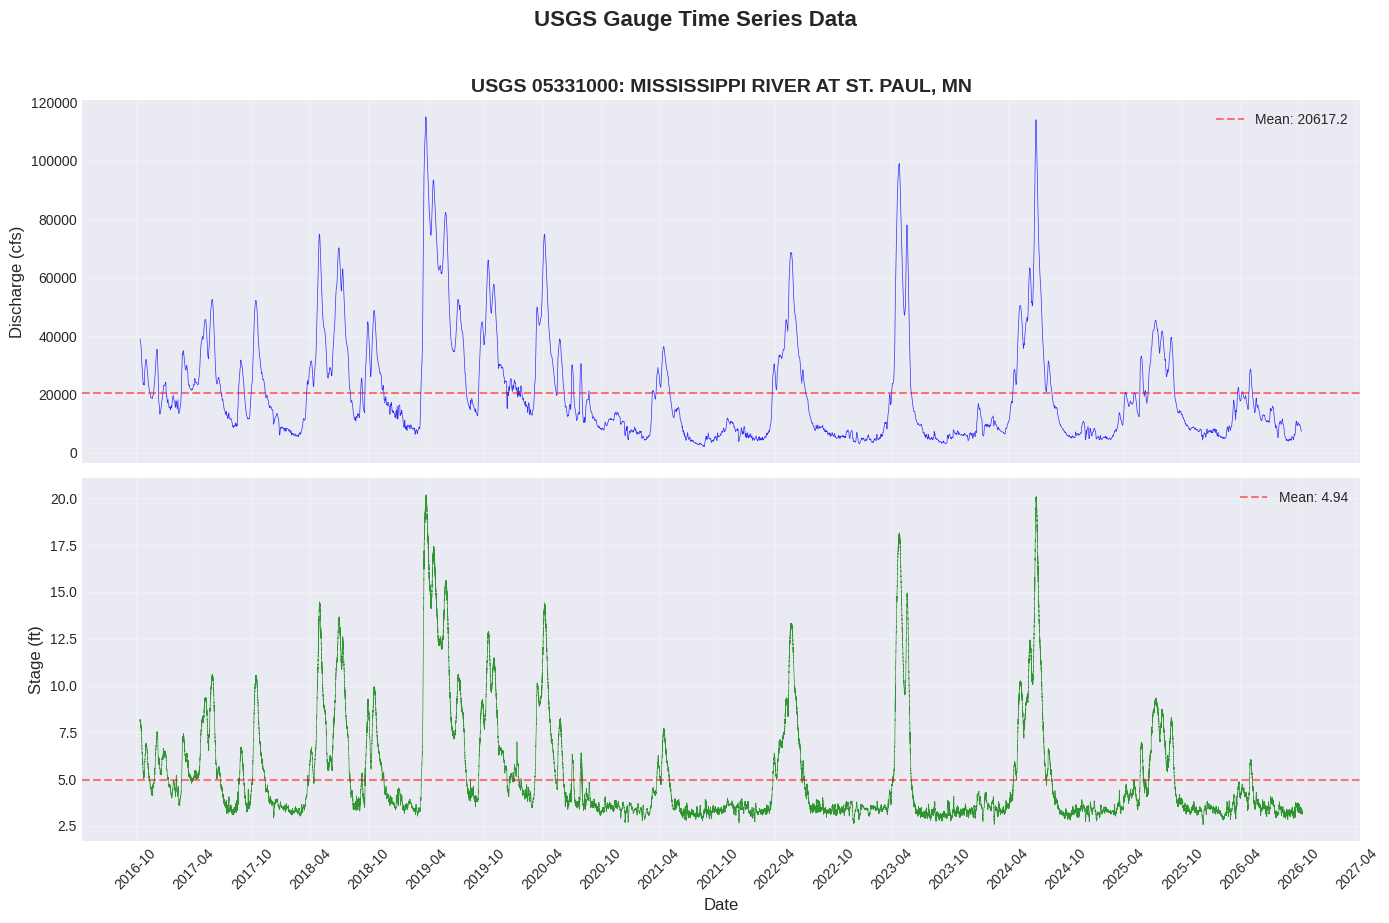

In [19]:
# Plot only the time series that were successfully retrieved
#
# Some gauges may have discharge data, stage data, both, or neither.
# This code checks what data are available before creating the plot.

# Create an empty list to store the time series we want to plot
series_to_plot = []

# Check whether discharge data were retrieved
if len(flow_df) > 0:

    # Find the discharge column
    #
    # USGS column names usually contain the parameter code.
    # 00060 = discharge
    discharge_col = [
        col for col in flow_df.columns
        if '00060' in col
    ][0]

    # Add discharge information to the plotting list
    series_to_plot.append({
        'name': 'Discharge',
        'data': flow_df,
        'col': discharge_col,
        'ylabel': 'Discharge (cfs)',
        'color': 'blue',
        'fmt': '{:.1f}'
    })

# Check whether stage data were retrieved
if len(stage_df) > 0:

    # Find the stage column
    #
    # 00065 = gage height / stage
    stage_col = [
        col for col in stage_df.columns
        if '00065' in col
    ][0]

    # Add stage information to the plotting list
    series_to_plot.append({
        'name': 'Stage',
        'data': stage_df,
        'col': stage_col,
        'ylabel': 'Stage (ft)',
        'color': 'green',
        'fmt': '{:.2f}'
    })

# If no data were retrieved, print a message instead of making an empty plot
if not series_to_plot:

    print("No time series data to visualize for this gauge.")

else:

    # Count how many panels we need
    #
    # One panel for discharge, one panel for stage,
    # or only one panel if only one dataset is available.
    n_panels = len(series_to_plot)

    # Create one subplot for each available time series
    #
    # sharex=True means all panels use the same date axis.
    # squeeze=False keeps the axes output consistent
    # even if there is only one panel.
    fig, axes = plt.subplots(
        n_panels,
        1,
        figsize=(14, 4.5 * n_panels),
        sharex=True,
        squeeze=False
    )

    # Convert axes into a simple 1D list
    #
    # This makes it easier to loop through the panels.
    axes = axes.flatten()

    # Loop through each subplot and each time series
    for ax, s in zip(axes, series_to_plot):

        # Plot the time series
        #
        # s['data'].index contains the dates/times
        # s['data'][s['col']] contains the values
        ax.plot(
            s['data'].index,
            s['data'][s['col']],
            color=s['color'],
            linewidth=0.5,
            alpha=0.8
        )

        # Add y-axis label
        ax.set_ylabel(s['ylabel'], fontsize=12)

        # Add grid lines to make the plot easier to read
        ax.grid(True, alpha=0.3)

        # Calculate the mean value for this time series
        mean_val = s['data'][s['col']].mean()

        # Add a horizontal dashed line showing the mean
        ax.axhline(
            y=mean_val,
            color='red',
            linestyle='--',
            alpha=0.5,
            label=f"Mean: {s['fmt'].format(mean_val)}"
        )

        # Show the legend
        ax.legend(loc='upper right')

    # Add a title to the top panel
    #
    # This includes the USGS site number and station name.
    axes[0].set_title(
        f'USGS {site_no}: {top_gauge["station_nm"]}',
        fontsize=14,
        fontweight='bold'
    )

    # Add x-axis label to the bottom panel
    axes[-1].set_xlabel('Date', fontsize=12)

    # Format dates on the x-axis
    #
    # DateFormatter controls how dates are displayed.
    # MonthLocator(interval=6) places a major tick every 6 months.
    axes[-1].xaxis.set_major_formatter(
        mdates.DateFormatter('%Y-%m')
    )

    axes[-1].xaxis.set_major_locator(
        mdates.MonthLocator(interval=6)
    )

    # Rotate x-axis labels so they are easier to read
    plt.xticks(rotation=45)

    # Add an overall title for the full figure
    plt.suptitle(
        'USGS Gauge Time Series Data',
        fontsize=16,
        fontweight='bold',
        y=1.02
    )

    # Automatically adjust spacing
    plt.tight_layout()

    # Display the final figure
    plt.show()

# Report any expected data types that were missing
#
# This helps the user understand why a panel may be missing.
missing = []

# If discharge data were not retrieved, add it to the missing list
if len(flow_df) == 0:
    missing.append('discharge (00060)')

# If stage data were not retrieved, add it to the missing list
if len(stage_df) == 0:
    missing.append('stage (00065)')

# Print a note if either discharge or stage is missing
if missing:

    print(
        f"\nNote: this gauge does not have "
        f"{' or '.join(missing)} for the selected window."
    )

    print(
        "The retrieval cells above skip missing parameters, "
        "and the plot above only shows what was returned."
    )

## Part 8: Data Processing and Quality Control 🔧

Daily values are smoothed by USGS, so they rarely show realistic gaps. To see how to handle gaps properly, we will work directly with the **instantaneous (15-minute)** record:

1. Pull a year of instantaneous discharge so we can see the seasonal pattern.
2. Zoom in on a recent 15-day window and resample to hourly for a cleaner plot.
3. Deliberately punch artificial gaps into that 15-day window so we can clearly demonstrate how linear interpolation fills them.

This three-step structure mirrors how you would actually QC a record on a real project: look at the long view, focus on a short window, then test your gap-fill rule on a known case before applying it to the full record.

### Step 1. Download a Year of Instantaneous Data

The cell below pulls one year of 15-minute discharge for the demo gauge and plots it so you can see the seasonal pattern and any obvious holes in the high-resolution record. The request usually takes 10 to 30 seconds.

🤖 **Try asking your AI:** *"What does `nwis.get_iv` return, and how do I tell whether the request succeeded versus returned an empty DataFrame?"*

Retrieving 1 year of instantaneous discharge for gauge 05331000...
Period: 2025-10-12 to 2026-10-12
This usually takes 10 to 30 seconds.

Retrieved 105,152 instantaneous measurements.


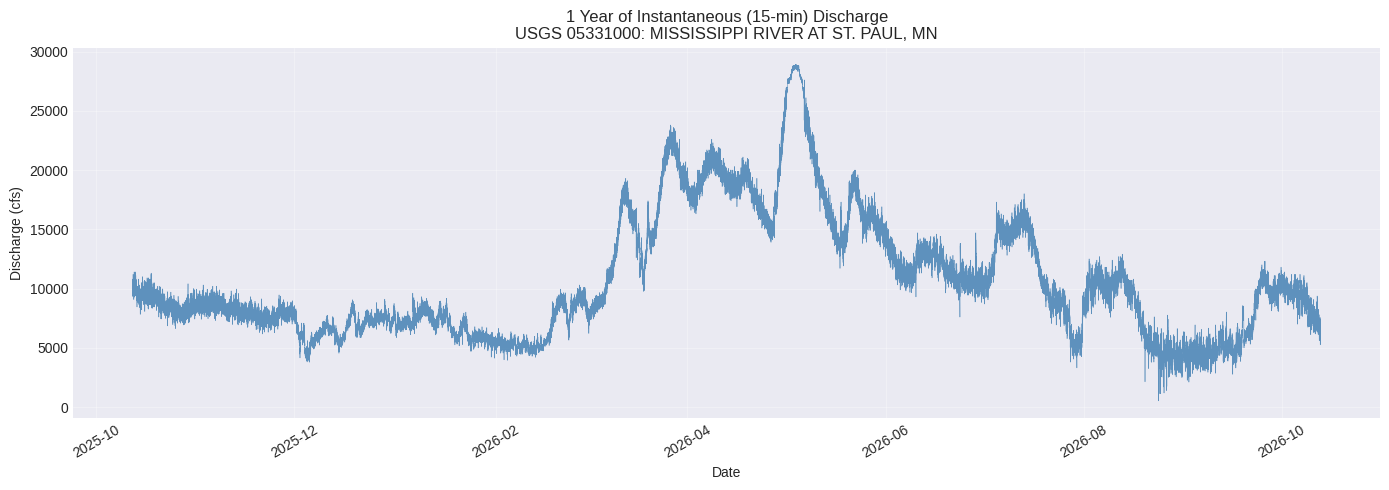

In [20]:
# Pull one year of instantaneous discharge data
#
# Instantaneous data are higher-frequency observations.
# For many USGS gauges, these data are collected every 15 minutes.
#
# This is useful when you want to see short-term flow changes,
# storm responses, peaks, and daily flow patterns.

# Define how many days of instantaneous data to request
iv_window_days = 365

# Set the end date as today
iv_end = datetime.now()

# Set the start date as 365 days before today
iv_start = iv_end - timedelta(days=iv_window_days)

# Create an empty DataFrame to store instantaneous discharge data
#
# This helps prevent errors later if the data request fails
# or if no data are returned.
flow_iv_df = pd.DataFrame()

# Check whether:
# 1. We have at least one gauge
# 2. Discharge data are available at that gauge
#
# USGS parameter code 00060 = discharge
if len(sites_in_buffer) > 0 and '00060' in available_params:

    # Print information about the request
    print(f"Retrieving 1 year of instantaneous discharge for gauge {site_no}...")
    print(
        f"Period: "
        f"{iv_start.strftime('%Y-%m-%d')} "
        f"to {iv_end.strftime('%Y-%m-%d')}"
    )

    # Let the user know this request may take a little time
    print("This usually takes 10 to 30 seconds.")

    # Use try/except so the notebook does not crash
    # if the request fails.
    try:

        # Request instantaneous discharge data from USGS NWIS
        #
        # get_iv() retrieves instantaneous values.
        #
        # sites = USGS site number
        # start = beginning date
        # end = ending date
        # parameterCd='00060' means discharge
        flow_iv_df, _ = nwis.get_iv(
            sites=site_no,
            start=iv_start.strftime('%Y-%m-%d'),
            end=iv_end.strftime('%Y-%m-%d'),
            parameterCd='00060'
        )

        # Check whether any records were returned
        if len(flow_iv_df) > 0:

            # Print how many observations were retrieved
            print(
                f"\nRetrieved "
                f"{len(flow_iv_df):,} instantaneous measurements."
            )

        else:

            # If no records were returned, print a helpful message
            print("\nUSGS returned no instantaneous records for this window.")

    # Catch and print retrieval errors
    except Exception as e:

        print(f"\nError retrieving instantaneous data: {e}")

else:

    # If discharge is not available, skip this step
    print(
        "Discharge is not available at this gauge; "
        "skipping the instantaneous pull."
    )

# Plot the full year of instantaneous discharge data
#
# Only create the plot if data were successfully retrieved.
if len(flow_iv_df) > 0:

    # Find the discharge column
    #
    # USGS column names often include the parameter code 00060.
    discharge_col_iv = [
        c for c in flow_iv_df.columns
        if '00060' in c
    ][0]

    # Create a figure and plotting area
    fig, ax = plt.subplots(figsize=(14, 5))

    # Plot the instantaneous discharge time series
    #
    # Because there are many observations, we use a thin line.
    ax.plot(
        flow_iv_df.index,
        flow_iv_df[discharge_col_iv],
        color='steelblue',
        linewidth=0.4,
        alpha=0.85
    )

    # Add x-axis label
    ax.set_xlabel('Date')

    # Add y-axis label
    ax.set_ylabel('Discharge (cfs)')

    # Add a title with the USGS site number and station name
    ax.set_title(
        f'1 Year of Instantaneous (15-min) Discharge\n'
        f'USGS {site_no}: {top_gauge["station_nm"]}',
        fontsize=12
    )

    # Add grid lines
    ax.grid(True, alpha=0.3)

    # Format the x-axis date labels
    #
    # DateFormatter controls how dates are displayed.
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter('%Y-%m')
    )

    # Show a major tick every 2 months
    ax.xaxis.set_major_locator(
        mdates.MonthLocator(interval=2)
    )

    # Rotate the date labels so they are easier to read
    plt.xticks(rotation=30)

    # Automatically adjust spacing
    plt.tight_layout()

    # Display the final plot
    plt.show()

### Step 2. Zoom In on the Most Recent 15 Days

A year of 15-minute data is great for context but too dense to read individual events or gaps from a plot. We zoom in on the **last 15 days** of the record and resample to **hourly** so each plot point is easy to see.

`resample('1h').mean()` groups all the 15-minute readings within each hour and averages them. Switching to `.max()` would keep peak intensity within each hour, which is often more useful for flood work.

🤖 **Try asking your AI:** *"When should I use `.mean()`, `.max()`, or `.sum()` when resampling streamflow to a coarser time step?"*

Focus window: 2026-09-27 23:00 to 2026-10-12 23:00
  Native 15-min records in window: 4,321
  Hourly slots after resampling: 361
  No real hourly gaps in this window.


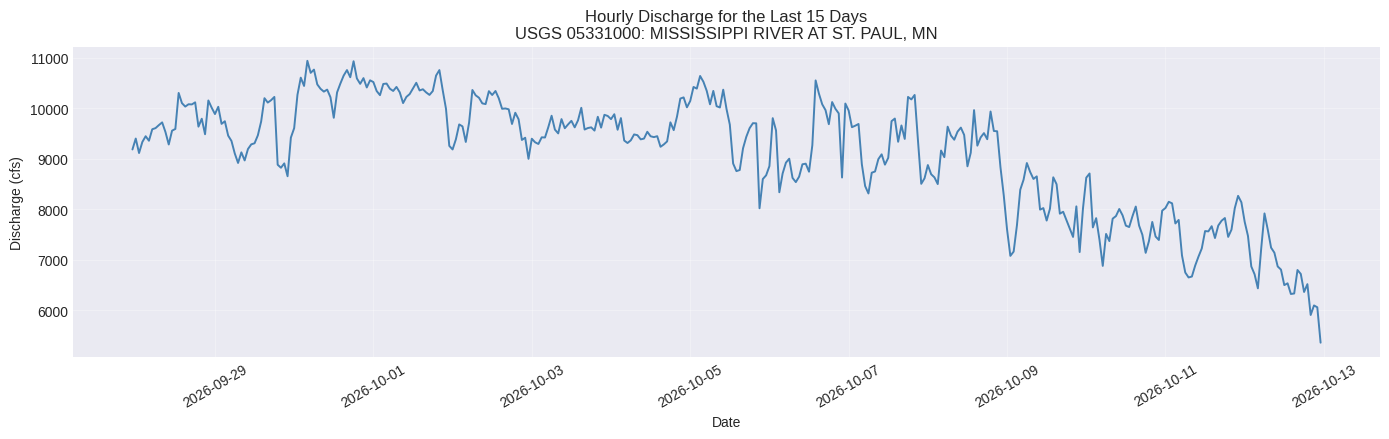

In [21]:
# Zoom in on the most recent 15-day window
# and resample instantaneous discharge data to hourly values
#
# Instantaneous data can be very detailed, often every 15 minutes.
# Resampling to hourly averages makes the plot easier to read
# while still preserving short-term changes in streamflow.

# Define the number of recent days to focus on
focus_days = 15

# Create a placeholder for the hourly data
#
# Starting with None makes it clear that hourly data
# will only exist if the resampling step is successful.
flow_hourly = None

# Check whether instantaneous discharge data exist
if len(flow_iv_df) == 0:

    # If no instantaneous data were retrieved,
    # skip this section and print a helpful message.
    print("No instantaneous data to zoom into; skipping the 15-day window.")

else:

    # Find the discharge column
    #
    # USGS discharge columns usually contain parameter code 00060.
    discharge_col_iv = [
        c for c in flow_iv_df.columns
        if '00060' in c
    ][0]

    # Find the end of the available instantaneous record
    #
    # This is the most recent timestamp in the dataset.
    focus_end = flow_iv_df.index.max()

    # Calculate the start of the focus window
    #
    # pd.Timedelta(days=focus_days) subtracts 15 days
    # from the most recent timestamp.
    focus_start = focus_end - pd.Timedelta(days=focus_days)

    # Select only the data within the focus window
    #
    # .loc[start:end] filters rows by date/time.
    # We keep only the discharge column.
    flow_focus_iv = flow_iv_df.loc[
        focus_start:focus_end,
        [discharge_col_iv]
    ]

    # Resample the 15-minute data to hourly average values
    #
    # '1h' means one-hour time intervals.
    # .mean() calculates the average discharge within each hour.
    flow_hourly = flow_focus_iv.resample('1h').mean()

    # Rename the discharge column to something simpler
    flow_hourly.columns = ['discharge_cfs']

    # Print the focus window dates
    print(
        f"Focus window: "
        f"{focus_start.strftime('%Y-%m-%d %H:%M')} "
        f"to {focus_end.strftime('%Y-%m-%d %H:%M')}"
    )

    # Print the number of original 15-minute records
    print(
        f"  Native 15-min records in window: "
        f"{len(flow_focus_iv):,}"
    )

    # Print the number of hourly records after resampling
    print(
        f"  Hourly slots after resampling: "
        f"{len(flow_hourly):,}"
    )

    # Count missing hourly values
    #
    # Missing values may indicate gaps in the original data.
    real_gaps = int(
        flow_hourly['discharge_cfs'].isna().sum()
    )

    # Print whether gaps were found
    if real_gaps > 0:

        print(f"  Real hourly gaps in this window: {real_gaps}")

    else:

        print(f"  No real hourly gaps in this window.")

    # Create a plot of the hourly discharge series
    fig, ax = plt.subplots(figsize=(14, 4.5))

    # Plot hourly discharge
    ax.plot(
        flow_hourly.index,
        flow_hourly['discharge_cfs'],
        color='steelblue',
        linewidth=1.4
    )

    # Add x-axis label
    ax.set_xlabel('Date')

    # Add y-axis label
    ax.set_ylabel('Discharge (cfs)')

    # Add plot title
    ax.set_title(
        f'Hourly Discharge for the Last {focus_days} Days\n'
        f'USGS {site_no}: {top_gauge["station_nm"]}',
        fontsize=12
    )

    # Add grid lines
    ax.grid(True, alpha=0.3)

    # Format x-axis dates as year-month-day
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter('%Y-%m-%d')
    )

    # Rotate date labels so they are easier to read
    plt.xticks(rotation=30)

    # Automatically adjust spacing
    plt.tight_layout()

    # Display the final plot
    plt.show()

### Step 3. Demonstration: Add Artificial Gaps and Fill Them

A clean 15-day window doesn't teach much about gap filling. To make the behavior clearly visible, we deliberately remove some hours from a copy of the data and run linear interpolation on the result.

**The gaps in the next cell are artificial. We are removing data on purpose so we can show what `interpolate(method='linear', limit=6)` does.** In a real project you would never remove your own data; this is purely a teaching exercise.

We punch in three gaps of different lengths so the limit behavior is visible:

- a 4-hour gap (shorter than the limit, fully filled)
- a 6-hour gap (equal to the limit, fully filled)
- a 12-hour gap (longer than the limit, partially filled)

🤖 **Try asking your AI:** *"What other interpolation methods does pandas `Series.interpolate` support, and when would I prefer time-weighted or spline over linear for hourly streamflow?"*

### Why limit how far we interpolate?

Linear interpolation draws a straight line between known values to estimate the missing ones. For short gaps of a few hours that's a reasonable approximation. But for longer gaps, like a week-long sensor failure during spring runoff, interpolation gives you a meaningless straight line right when the data matters most.

In the demonstration above, the `limit=6` argument capped this. The 4-hour and 6-hour artificial gaps were filled in full; the 12-hour gap was filled for its first 6 hours, and the remaining 6 stayed as NaN (shown by the red band).

In a real project you would review those longer gaps and decide whether to fill them from a nearby gauge, leave them empty, or flag the period as unreliable.

ARTIFICIAL GAP DEMONSTRATION (these gaps are fabricated for teaching)
Punched 3 gaps of lengths [4, 6, 12] hours.
Interpolation: method='linear', limit=6 (hours).
  Filled:   16 hours
  Left NaN: 6 hours  (gap longer than the limit)


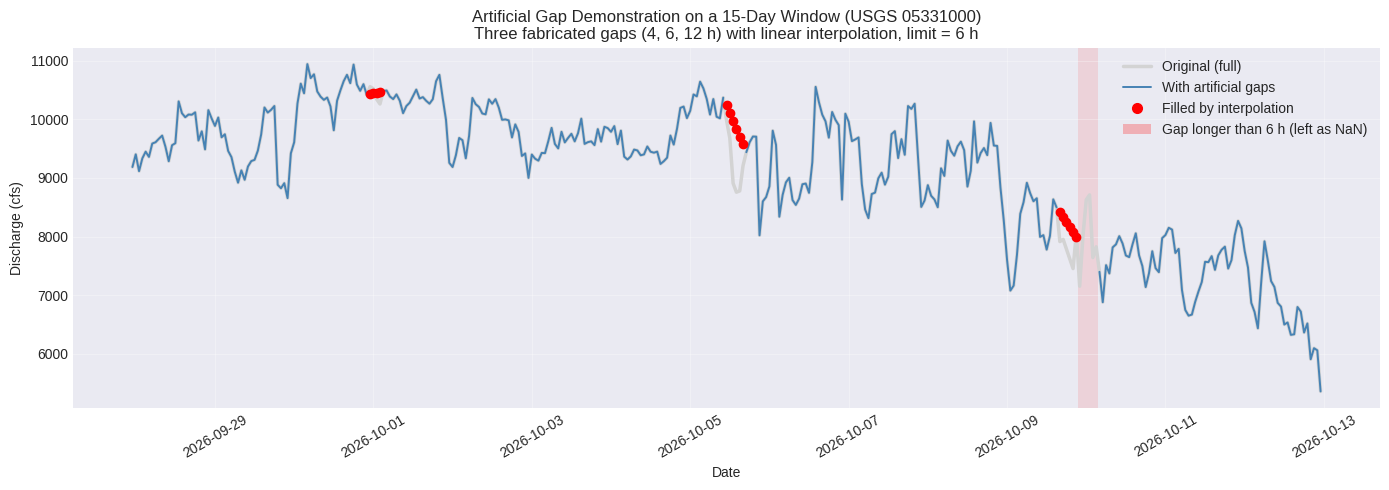

In [22]:
# Import NumPy
#
# NumPy is used here for:
# - creating missing values with np.nan
# - basic array-style calculations
import numpy as np

# Import Patch for custom legend entries
#
# Patch allows us to add a colored box
# to the plot legend.
from matplotlib.patches import Patch

# Create a placeholder for the filled hourly discharge data
#
# This variable is used later in the save/export step.
#
# We start it as None in case the interpolation step
# does not run because there is not enough hourly data.
flow_hourly_filled = None

# Check whether we have enough hourly data
#
# If flow_hourly does not exist or has too few rows,
# we skip the artificial-gap demonstration.
if flow_hourly is None or len(flow_hourly) < 50:

    print("Not enough hourly data for the artificial-gap demo.")

else:

    # -------------------------------------------------------------------------
    # CREATE ARTIFICIAL GAPS
    # -------------------------------------------------------------------------

    # Make a copy of the hourly discharge data
    #
    # We do not want to modify the original flow_hourly dataset.
    flow_demo = flow_hourly.copy()

    # Count the number of rows in the hourly dataset
    n = len(flow_demo)

    # Define artificial gaps to insert into the time series
    #
    # Each tuple contains:
    # - starting location in the dataset
    # - gap length in hours
    #
    # These gaps are created only for teaching purposes.
    gap_specs = [
        (int(0.20 * n),  4),   # short gap: fully filled by limit=6
        (int(0.50 * n),  6),   # equal to limit: fully filled
        (int(0.78 * n), 12),   # longer gap: only partially filled
    ]

    # Loop through each artificial gap
    for start_idx, length_h in gap_specs:

        # Calculate the ending index for the gap
        #
        # min() prevents the end index from going
        # beyond the length of the dataset.
        end_idx = min(start_idx + length_h, n)

        # Replace discharge values with NaN
        #
        # NaN means "missing value".
        #
        # .iloc selects rows by position.
        # The 0 means the first column, which is discharge_cfs.
        flow_demo.iloc[start_idx:end_idx, 0] = np.nan

    # -------------------------------------------------------------------------
    # FILL SHORT GAPS USING LINEAR INTERPOLATION
    # -------------------------------------------------------------------------

    # Make a copy of the gapped dataset
    #
    # This copy will store the interpolated values.
    flow_demo_filled = flow_demo.copy()

    # Fill missing discharge values using linear interpolation
    #
    # method='linear' estimates missing values using a straight line
    # between known values before and after the gap.
    #
    # limit=6 means only gaps up to 6 consecutive hourly values
    # will be filled completely.
    flow_demo_filled['discharge_cfs'] = (
        flow_demo_filled['discharge_cfs'].interpolate(
            method='linear',
            limit=6
        )
    )

    # Identify which missing values were artificially created
    #
    # This compares:
    # - flow_demo: the dataset with artificial gaps
    # - flow_hourly: the original complete hourly dataset
    was_artificial = (
        flow_demo['discharge_cfs'].isna() &
        flow_hourly['discharge_cfs'].notna()
    )

    # Identify artificial gaps that were filled by interpolation
    filled_mask = (
        was_artificial &
        flow_demo_filled['discharge_cfs'].notna()
    )

    # Identify artificial gaps that remain unfilled
    #
    # These are usually part of gaps longer than the interpolation limit.
    unfilled_mask = (
        was_artificial &
        flow_demo_filled['discharge_cfs'].isna()
    )

    # Print a summary of the artificial-gap demonstration
    print("ARTIFICIAL GAP DEMONSTRATION (these gaps are fabricated for teaching)")
    print("=" * 60)
    print(f"Punched 3 gaps of lengths {[g[1] for g in gap_specs]} hours.")
    print("Interpolation: method='linear', limit=6 (hours).")
    print(f"  Filled:   {int(filled_mask.sum())} hours")
    print(f"  Left NaN: {int(unfilled_mask.sum())} hours  (gap longer than the limit)")

    # -------------------------------------------------------------------------
    # PLOT ORIGINAL DATA, GAPS, AND INTERPOLATED VALUES
    # -------------------------------------------------------------------------

    # Create a figure and plotting area
    fig, ax = plt.subplots(figsize=(14, 5))

    # Plot the original complete hourly data in light gray
    #
    # This shows what the full record looked like
    # before we created artificial gaps.
    ax.plot(
        flow_hourly.index,
        flow_hourly['discharge_cfs'],
        color='lightgray',
        linewidth=2.5,
        zorder=1
    )

    # Plot the time series after artificial gaps were inserted
    #
    # Missing gaps will appear as breaks in the blue line.
    ax.plot(
        flow_demo.index,
        flow_demo['discharge_cfs'],
        color='steelblue',
        linewidth=1.4,
        zorder=2
    )

    # Plot red dots where interpolation filled missing values
    if filled_mask.any():

        ax.scatter(
            flow_demo_filled.index[filled_mask],
            flow_demo_filled.loc[filled_mask, 'discharge_cfs'],
            color='red',
            s=36,
            zorder=4
        )

    # Highlight missing values that were not filled
    #
    # These remain missing because the gap was longer
    # than the interpolation limit.
    if unfilled_mask.any():

        for ts in flow_demo_filled.index[unfilled_mask]:

            ax.axvspan(
                ts - pd.Timedelta(minutes=30),
                ts + pd.Timedelta(minutes=30),
                facecolor='red',
                alpha=0.10,
                zorder=0
            )

    # Create a custom legend
    #
    # This gives us clearer labels than the automatic legend.
    legend_handles = [
        plt.Line2D(
            [0],
            [0],
            color='lightgray',
            linewidth=2.5,
            label='Original (full)'
        ),
        plt.Line2D(
            [0],
            [0],
            color='steelblue',
            linewidth=1.4,
            label='With artificial gaps'
        ),
        plt.Line2D(
            [0],
            [0],
            marker='o',
            color='red',
            linestyle='None',
            markersize=7,
            label='Filled by interpolation'
        ),
        Patch(
            facecolor='red',
            alpha=0.25,
            label='Gap longer than 6 h (left as NaN)'
        ),
    ]

    # Add legend to the plot
    ax.legend(
        handles=legend_handles,
        loc='upper right',
        fontsize=10,
        framealpha=0.9
    )

    # Add x-axis label
    ax.set_xlabel('Date')

    # Add y-axis label
    ax.set_ylabel('Discharge (cfs)')

    # Add title
    ax.set_title(
        f'Artificial Gap Demonstration on a 15-Day Window (USGS {site_no})\n'
        f'Three fabricated gaps (4, 6, 12 h) with linear interpolation, limit = 6 h',
        fontsize=12
    )

    # Add grid lines
    ax.grid(True, alpha=0.3)

    # Format x-axis dates
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter('%Y-%m-%d')
    )

    # Rotate date labels
    plt.xticks(rotation=30)

    # Automatically adjust spacing
    plt.tight_layout()

    # Display the final plot
    plt.show()

    # -------------------------------------------------------------------------
    # APPLY THE SAME INTERPOLATION APPROACH TO THE REAL HOURLY DATA
    # -------------------------------------------------------------------------

    # Make a copy of the real hourly dataset
    flow_hourly_filled = flow_hourly.copy()

    # Fill short gaps in the real hourly dataset
    #
    # This prepares a cleaner dataset for the save/export step later.
    flow_hourly_filled['discharge_cfs'] = (
        flow_hourly_filled['discharge_cfs'].interpolate(
            method='linear',
            limit=6
        )
    )

## Part 9: Creating Professional Outputs 📂

### Generate Gauge Catalog

In [23]:
# Check whether there are gauges to save
#
# If sites_in_buffer is empty, there is no gauge catalog
# or spatial data to export.
if len(sites_in_buffer) > 0:

    # Create an output folder
    #
    # Path() creates a folder/file path object.
    # This is often cleaner than writing file paths as strings.
    output_dir = Path('USGS_Gauge_Data')

    # Create the folder if it does not already exist
    #
    # exist_ok=True prevents an error if the folder already exists.
    output_dir.mkdir(exist_ok=True)

    # Print progress messages
    print("Creating USGS Gauge Data catalog...")
    print(f"Output directory: {output_dir}")

    # Create a gauge catalog table
    #
    # This keeps only the most useful columns for a summary CSV file.
    catalog_df = sites_in_buffer[
        [
            'site_no',
            'station_nm',
            'dec_lat_va',
            'dec_long_va',
            'distance_km',
            'location_type',
            'rank'
        ]
    ].copy()

    # Add drainage area if that column exists
    #
    # Some USGS sites may not include drainage area information.
    if 'drain_area_va' in sites_in_buffer.columns:

        catalog_df['drainage_area_sqmi'] = (
            sites_in_buffer['drain_area_va']
        )

    # Define the output path for the CSV catalog
    catalog_path = output_dir / 'gauge_catalog.csv'

    # Save the gauge catalog as a CSV file
    #
    # index=False prevents pandas from writing row numbers
    # as an extra column.
    catalog_df.to_csv(
        catalog_path,
        index=False
    )

    # Print confirmation message
    print(f"  Saved gauge catalog: {catalog_path}")

    # Define the output path for the gauge locations GeoJSON
    geojson_path = output_dir / 'gauge_locations.geojson'

    # Save gauge locations as a GeoJSON file
    #
    # GeoJSON can be opened in many GIS tools
    # and web mapping applications.
    sites_in_buffer.to_file(
        geojson_path,
        driver='GeoJSON'
    )

    # Print confirmation message
    print(f"  Saved gauge locations: {geojson_path}")

    # Define the output path for the study area boundary
    boundary_path = output_dir / 'watershed_boundary.geojson'

    # Save the study area watershed boundary as GeoJSON
    selected_watershed_wgs.to_file(
        boundary_path,
        driver='GeoJSON'
    )

    # Print confirmation message
    print(f"  Saved watershed boundary: {boundary_path}")

    # Define the output path for the search buffer boundary
    buffer_path = output_dir / 'watershed_buffer.geojson'

    # Save the buffered study area as GeoJSON
    buffered_watershed_wgs.to_file(
        buffer_path,
        driver='GeoJSON'
    )

    # Print confirmation message
    print(f"  Saved buffer boundary: {buffer_path}")

Creating USGS Gauge Data catalog...
Output directory: USGS_Gauge_Data
  Saved gauge catalog: USGS_Gauge_Data/gauge_catalog.csv
  Saved gauge locations: USGS_Gauge_Data/gauge_locations.geojson
  Saved watershed boundary: USGS_Gauge_Data/watershed_boundary.geojson
  Saved buffer boundary: USGS_Gauge_Data/watershed_buffer.geojson


### What did we just create?

The gauge catalog is a CSV file listing every gauge found in the search area with its coordinates, distance, and location type. This is a standard deliverable in the early stages of an H&H project; it tells your team what data is available before you start modeling.

The GeoJSON files can be loaded into any GIS software or shared with colleagues who want to visualize the search area in their own tools.

🤖 **Try asking your AI:** *"How do I turn the gauge catalog CSV into an Excel workbook with one tab for the catalog and one tab for each gauge's hourly data?"*

### Where are the saved files in Google Colab?

All exported files were saved inside the `USGS_Gauge_Data` folder in your current Colab session.

To view them:

1. Open the **Files** panel on the left side of Google Colab
2. Expand the `USGS_Gauge_Data` folder
3. Open the folder for your selected gauge (for example `USGS-05331000`)

You should see files such as:
- `gauge_catalog.csv`
- `gauge_locations.geojson`
- `historical_flow_daily.csv`
- `recent_flow_hourly_filled.csv`
- `historical_stage.csv`
- `metadata.json`

You can:
- download the files to your computer
- inspect them directly in Colab
- use them in later notebooks or GIS software

💡 Important: Files stored in a Colab session are temporary. If you restart the runtime, the files may be deleted unless you download them or save them to Google Drive.

### Save Time Series Data for Top Gauge

In [24]:
# Check whether:
# 1. We have at least one gauge
# 2. We successfully retrieved discharge data
#
# If either condition fails, there is nothing to save.
if len(sites_in_buffer) > 0 and len(flow_df) > 0:

    # Create a folder for this specific USGS gauge
    #
    # Example folder name:
    # USGS-05331000
    gauge_dir = output_dir / f'USGS-{site_no}'

    # Create the folder if it does not already exist
    gauge_dir.mkdir(exist_ok=True)

    # Print progress message
    print(f"\nSaving data for gauge {site_no}...")

    # -------------------------------------------------------------------------
    # SAVE BASIC METADATA
    # -------------------------------------------------------------------------

    # Create a dictionary containing important metadata
    #
    # Metadata describes the gauge and the retrieval process.
    metadata = {

        # USGS site number
        'site_no': site_no,

        # Station name
        'station_name': top_gauge['station_nm'],

        # Latitude and longitude
        #
        # float() converts NumPy types into standard Python numbers
        # so they can be saved into JSON files.
        'latitude': float(top_gauge['dec_lat_va']),
        'longitude': float(top_gauge['dec_long_va']),

        # Distance from watershed centroid
        'distance_km': float(top_gauge['distance_km']),

        # Whether the gauge is inside the watershed
        # or only inside the search buffer
        'location_type': top_gauge['location_type'],

        # Timestamp showing when the data were retrieved
        'data_retrieved': datetime.now().isoformat()
    }

    # Define output path for metadata JSON
    metadata_path = gauge_dir / 'metadata.json'

    # Save metadata as a JSON file
    #
    # JSON is a lightweight text format commonly used
    # for APIs and structured metadata.
    with open(metadata_path, 'w') as f:

        json.dump(
            metadata,
            f,
            indent=2
        )

    # Print confirmation message
    print(f"  Saved metadata: {metadata_path}")

    # -------------------------------------------------------------------------
    # SAVE HISTORICAL DAILY DISCHARGE DATA
    # -------------------------------------------------------------------------

    # Find the discharge column
    #
    # USGS discharge columns usually contain "00060".
    discharge_col = [
        c for c in flow_df.columns
        if '00060' in c
    ][0]

    # Create a clean export DataFrame
    #
    # Keep only the discharge column.
    historical_daily = flow_df[[discharge_col]].copy()

    # Rename the column to something simpler and cleaner
    historical_daily.columns = ['discharge_cfs']

    # Define output file path
    daily_path = gauge_dir / 'historical_flow_daily.csv'

    # Save daily discharge as CSV
    historical_daily.to_csv(daily_path)

    # Print confirmation message
    print(f"  Saved historical daily flow: {daily_path}")

    # -------------------------------------------------------------------------
    # SAVE RECENT GAP-FILLED HOURLY DATA
    # -------------------------------------------------------------------------

    # Save the hourly dataset only if it exists
    #
    # This dataset came from the Part 8 instantaneous retrieval
    # and interpolation step.
    if flow_hourly_filled is not None:

        # Define output path
        hourly_path = (
            gauge_dir / 'recent_flow_hourly_filled.csv'
        )

        # Save the hourly discharge data
        flow_hourly_filled.to_csv(hourly_path)

        # Print confirmation message
        print(
            f"  Saved recent hourly flow "
            f"(gap-filled): {hourly_path}"
        )

    # -------------------------------------------------------------------------
    # SAVE STAGE DATA IF AVAILABLE
    # -------------------------------------------------------------------------

    # Only save stage data if stage retrieval was successful
    if len(stage_df) > 0:

        # Find the stage column
        #
        # USGS stage columns usually contain "00065".
        stage_col = [
            c for c in stage_df.columns
            if '00065' in c
        ][0]

        # Create a clean export DataFrame
        stage_export = stage_df[[stage_col]].copy()

        # Rename the column
        stage_export.columns = ['stage_ft']

        # Define output path
        stage_path = gauge_dir / 'historical_stage.csv'

        # Save stage data as CSV
        stage_export.to_csv(stage_path)

        # Print confirmation message
        print(f"  Saved stage data: {stage_path}")

    # -------------------------------------------------------------------------
    # CREATE A DATA AVAILABILITY SUMMARY
    # -------------------------------------------------------------------------

    # Create a dictionary describing what datasets exist
    # and their date ranges.
    availability = {

        # Daily discharge dataset summary
        'flow_daily': {

            # First timestamp in the dataset
            'start_date': str(flow_df.index.min()),

            # Last timestamp in the dataset
            'end_date': str(flow_df.index.max()),

            # Number of records
            'record_count': len(flow_df),
        }
    }

    # Add hourly dataset information if available
    if flow_hourly_filled is not None:

        availability['flow_hourly_recent'] = {

            'start_date': str(flow_hourly_filled.index.min()),
            'end_date': str(flow_hourly_filled.index.max()),
            'record_count': len(flow_hourly_filled),
        }

    # Add stage dataset summary if available
    if len(stage_df) > 0:

        availability['stage'] = {

            'start_date': str(stage_df.index.min()),
            'end_date': str(stage_df.index.max()),
            'record_count': len(stage_df),
        }

    # Define output path for the availability summary
    availability_path = gauge_dir / 'data_availability.json'

    # Save availability summary as JSON
    with open(availability_path, 'w') as f:

        json.dump(
            availability,
            f,
            indent=2
        )

    # Print confirmation message
    print(f"  Saved availability summary: {availability_path}")


Saving data for gauge 05331000...
  Saved metadata: USGS_Gauge_Data/USGS-05331000/metadata.json
  Saved historical daily flow: USGS_Gauge_Data/USGS-05331000/historical_flow_daily.csv
  Saved recent hourly flow (gap-filled): USGS_Gauge_Data/USGS-05331000/recent_flow_hourly_filled.csv
  Saved stage data: USGS_Gauge_Data/USGS-05331000/historical_stage.csv
  Saved availability summary: USGS_Gauge_Data/USGS-05331000/data_availability.json


## Practice Exercises 🎯

Now it is your turn. These four exercises map directly onto what you just built: watershed gauge discovery, real time series retrieval, the 15-day artificial gap-fill demo, and packaging the results into a reusable function.

For each exercise, write your code in the cell below the description, run it, and check the output. Ask your AI assistant whenever you get stuck; the prompts above each exercise are starting points.

### Exercise 1: Compare three gauges in the watershed

Pick the **top three gauges** by rank from `sites_in_buffer` and retrieve **daily discharge** for the last 5 years for each one. Plot all three hydrographs on the same axes. Print a short table with site number, station name, mean discharge, and number of records for each gauge.

🤖 **Try asking your AI:** *"Loop over a list of USGS site numbers, call `nwis.get_dv` for each, and combine the results into a long-format DataFrame with columns `site_no`, `date`, and `discharge_cfs`."*

In [25]:
# EXERCISE 1: Compare three gauges in the watershed
# Your code here.
#
# Steps:
# 1. Get the top three site numbers from sites_in_buffer (the `site_no` column).
# 2. Loop over them and call nwis.get_dv for parameterCd='00060' over the last 5 years.
# 3. Plot all three discharge series on a single matplotlib axes.
# 4. Print a small comparison table (site, name, mean discharge, n records).

### Exercise 2: Apply the gap-fill demo to STAGE data

Repeat the year -> 15-day -> artificial-gap workflow from Part 8, but for **stage (parameter 00065)** instead of discharge. Use the same demo gauge (`site_no`).

You will need to:

- Pull one year of instantaneous stage with `nwis.get_iv(..., parameterCd='00065')`.
- Subset to the last 15 days and resample to hourly.
- Punch in three artificial gaps (4, 6, and 12 hours) and run `interpolate(method='linear', limit=6)`.
- Plot the result the same way the demonstration cell does.

If the gauge has no stage data, print a clear message and pick another gauge from `sites_in_buffer` that does.

🤖 **Try asking your AI:** *"Adapt the artificial gap demonstration to work on a stage series in feet. Keep the same 4/6/12-hour gap pattern and `limit=6` interpolation but change the labels and units."*

In [26]:
# EXERCISE 2: Apply the gap-fill demo to stage data
# Your code here.
#
# Steps:
# 1. Check that 00065 is in available_params (or pick a gauge that has it).
# 2. Pull one year of instantaneous stage with nwis.get_iv.
# 3. Subset to the last 15 days, resample to hourly.
# 4. Punch artificial gaps (4, 6, 12 h) and interpolate with limit=6.
# 5. Plot original + with-gaps + filled points + unfilled bands.

### Exercise 3: Use a different HUC-8 watershed

You loaded all 80 Minnesota HUC-8 watersheds into `watersheds`, but used only one. Pick a different basin and run the whole discovery flow on it.

Steps:

1. Browse the basins with `watersheds[['HUC_8', 'major_name']].sort_values('major_name')`.
2. Choose a different `HUC_8` code. For example, `07020012` (Lower Minnesota River) or `07040001` (Mississippi River - Lake Pepin).
3. Set `selected_watershed` to that basin, then re-run the CRS step (Part 5), the buffer (Part 5), and the gauge search (Part 6).
4. How many gauges does the new basin contain?

🤖 **Try asking your AI:** *"Write a function `pick_watershed(huc8)` that filters the `watersheds` GeoDataFrame to one HUC-8 code and returns it, raising a clear error if the code is not present."*

In [27]:
# EXERCISE 3: Use a different HUC-8 watershed
# Your code here.
#
# Steps:
# 1. Browse the basins:
#    watersheds[['HUC_8', 'major_name']].sort_values('major_name')
# 2. Pick a different HUC_8 code, e.g. '07020012' or '07040001'.
# 3. Filter to it:
#    selected_watershed = watersheds[watersheds['HUC_8'].astype(str) == YOUR_CODE].copy()
# 4. Re-run the CRS step (Part 5), the buffer, and the gauge search (Part 6).
# 5. Print how many gauges fall in the new watershed and list their site numbers.

### Exercise 4: Write a `gauge_report(site_no)` function

Wrap the discovery-to-summary workflow into a reusable function. Calling `gauge_report('05331000')` should return a dictionary with:

- `site_no`, `station_nm`, `latitude`, `longitude`
- `parameters_available` (list of parameter codes from the series catalog)
- `flow_records_daily` (count of daily discharge records for the last 10 years)
- `flow_mean_cfs`, `flow_max_cfs`
- `pct_missing_hourly_15day` (percentage of NaN hours in the most recent 15 days, before any gap fill)

Bonus: have the function pretty-print the dictionary as a small Markdown report.

🤖 **Try asking your AI:** *"Write a Python function that takes a USGS site number and returns a small summary dictionary. Include type hints, a docstring, and handle the case where the gauge has no discharge data."*

In [28]:
# EXERCISE 4: Write a gauge_report(site_no) function
# Your code here.
#
# Skeleton to start from:
#
# def gauge_report(site_no: str) -> dict:
#     """Return a small summary report for one USGS gauge."""
#     report = {'site_no': site_no}
#     # ... fill in the rest ...
#     return report
#
# Test it with: gauge_report('05331000')

### Exercise 5: Debug This Snippet with AI 🔍

The function in the next cell is supposed to resample an hourly discharge series to a **daily mean**. It runs without errors and produces numbers that look plausible at first glance, but they are not the daily mean. This is a common pandas pitfall when moving between time steps.

Run the cell, compare the two columns side by side, then paste the function into your AI assistant with a clear question. The point of this exercise is to practice the **run, observe, paste, ask, fix** loop you'll use every day.

**Suggested AI prompt:**

> *"Here is a Python function and the result it produced. It's supposed to resample hourly discharge to a daily mean, but the values are about 24 times larger than they should be. Find the bug and show me a fixed version with a short explanation.*
> *```
> def buggy_resample_to_daily(hourly_df):
>     return hourly_df.resample('1D').sum()
> ```*
> *Hourly values are around 12,000 cfs; the buggy daily numbers are around 280,000."*

In [29]:
# === Exercise 5: Debug This Snippet with AI ===
#
# The function below is supposed to resample hourly discharge to a daily mean.
# It runs fine but the numbers are way too big. Run this cell, compare the
# two series side by side, then paste the function into your AI assistant
# with the prompt above to find and fix the bug.

def buggy_resample_to_daily(hourly_df):
    """Resample an hourly discharge DataFrame to a daily mean."""
    return hourly_df.resample('1D').sum()   # the bug lives on this line


if flow_hourly is None or len(flow_hourly) < 24:
    print("This exercise needs the hourly series from Part 8. Run the Part 8 cells first.")
else:
    buggy   = buggy_resample_to_daily(flow_hourly).rename(columns={'discharge_cfs': 'buggy_daily'})
    correct = flow_hourly.resample('1D').mean().rename(columns={'discharge_cfs': 'correct_daily_mean'})

    comparison = pd.concat([buggy, correct], axis=1).head(7)
    print("First week of resampled discharge (cfs):\n")
    print(comparison.round(1))
    print()
    print("The buggy column is roughly 24 times the correct one.")
    print("Hint: what method aggregates 24 hourly readings into one daily value?")

First week of resampled discharge (cfs):

                           buggy_daily  correct_daily_mean
datetime                                                  
2026-09-27 00:00:00+00:00       9186.7              9186.7
2026-09-28 00:00:00+00:00     233030.8              9709.6
2026-09-29 00:00:00+00:00     226698.3              9445.8
2026-09-30 00:00:00+00:00     251356.7             10473.2
2026-10-01 00:00:00+00:00     247771.7             10323.8
2026-10-02 00:00:00+00:00     236273.3              9844.7
2026-10-03 00:00:00+00:00     231218.3              9634.1

The buggy column is roughly 24 times the correct one.
Hint: what method aggregates 24 hourly readings into one daily value?


## That's Module 5 Done!

Think about what you just automated. Finding gauges, downloading data, filling gaps, formatting for model input. That used to take hours of clicking through the USGS website and cleaning data in Excel. Now it runs in a few minutes.

### What you can do now

- **Data discovery.** Find all USGS gauges near any watershed, filter by data availability, rank by relevance.
- **Time series retrieval.** Pull discharge and stage at the right time step, with a series-catalog-driven fallback when a parameter is missing.
- **Quality control.** Move from a long instantaneous record to a focused window, identify gaps, and apply a sensible interpolation rule with a configurable limit.
- **Reusable outputs.** Save a gauge catalog and per-gauge CSV/JSON files ready for HEC-RAS, HEC-HMS, or any other downstream tool.

### Next steps

- **Module 6:** Precipitation data and design storms with NOAA Atlas 14.
- **On your own:** Try the workflow on a watershed from a current project. Once you have one good script, every future project starts from a copy.

The full repository, including data files and the rest of the course, is at [github.com/mohsennasab/python-fundamentals-hh](https://github.com/mohsennasab/python-fundamentals-hh).

### Why limit how far we interpolate?

Linear interpolation draws a straight line between known values to estimate the missing ones. For short gaps of a few hours that's a reasonable approximation. But for longer gaps, like a week-long sensor failure during spring runoff, interpolation gives you a meaningless straight line right when the data matters most.

In the demonstration above, the `limit=6` argument capped this. The 4-hour and 6-hour artificial gaps were filled in full; the 12-hour gap was filled for its first 6 hours, and the remaining 6 stayed as NaN (shown by the red band).

In a real project you would review those longer gaps and decide whether to fill them from a nearby gauge, leave them empty, or flag the period as unreliable.

🤖 **Try asking your AI:** *"Show me a function that fills gaps in a USGS hourly discharge series using values from a nearby reference gauge instead of interpolation, scaled by drainage area."*